<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QAE_AnomalyDetection_Hdaib2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum autoencoder frameworks for network anomaly detection: Hdaib, Rajasegarar and Pan (2024) step by step

This notebook re-implements, runs and checks the method of

> Moe Hdaib, Sutharshan Rajasegarar and Lei Pan, "Quantum deep learning-based anomaly detection for enhanced network
> security", *Quantum Machine Intelligence* 6:26, 2024. DOI 10.1007/s42484-024-00163-2 (open access).

The paper publishes no code ("available from the corresponding author upon request"). Everything below is written from
the paper's description with the software stack the paper names: PennyLane for the quantum autoencoder, Qiskit for the
quantum kernel and the variational classifiers, scikit-learn for preprocessing, the classical counterparts and the metrics.

**What the notebook does.** It downloads the KDD Cup 1999 data (the first of the paper's three datasets and the only one
small enough for a classroom), applies the paper's preprocessing (one-hot encoding, undersampling, min-max normalisation,
PCA to the number of qubits, 80 : 20 split), trains a **quantum autoencoder (QAE)** with a SWAP-test cost on normal
connections only, and feeds the QAE's latent representation to the paper's three detectors: **Framework 1** a one-class
SVM with a quantum (ZZFeatureMap fidelity) kernel, **Framework 2** a "quantum random forest" (a bootstrap ensemble of
variational quantum classifiers with majority vote) and **Framework 3** a quantum k-nearest-neighbour classifier whose
similarity is the SWAP-test fidelity between encoded states. The paper's naive reconstruction-error detector and its
classical counterparts (one-class SVM, random forest, kNN, Table 4) run on the same latent features, a random forest and
an RBF-SVM also run on the raw PCA inputs, the QAE's fidelity-versus-qubit-count table (Table 2) is re-measured, and the
last section puts the paper's KDD99 rows of Table 1, Table 2 and Table 4 next to our numbers with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
pinned Qiskit and PennyLane versions; if Colab asks to restart the session, restart and run all again. No GPU and no
quantum-cloud account are needed; everything is simulated with statevectors (the paper used the `ibmq_lima` device for
the kernel circuit, which is retired).

**Runtime.** With `FAST_MODE = True` (1,000 connections, 30 QAE epochs, 3 trees, 3 repeated draws) the notebook takes
about 5 minutes on a laptop CPU, 5-10 minutes on Colab. With `FAST_MODE = False` (3,000 connections, 100 QAE epochs,
5 trees, 5 repeated draws) it takes 30-45 minutes. The runtime of the committed run is printed at the end of the notebook.

**What you get at the end.** Accuracy, precision, recall and F1 (attack = positive class) for the three quantum
frameworks, the naive detector and five classical models on identical inputs, confusion matrices, per-attack-family
detection rates, mean +- std over repeated balanced draws, the circuits of the paper's Fig. 4-7 drawn from code, and a
comparison table with an explicit verdict for every number of the paper that can be checked.

## The paper in one page

**Problem.** Flag anomalous (attack) connections in computer and IoT network traffic without needing many labelled
attacks: an unsupervised anomaly-detection setting in which a model of *normal* traffic is learned and deviations are
reported.

**Decision.** Normal versus anomaly, per connection record.

**Method (Section 4, Fig. 3).** Preprocessing -> PCA to the number of available qubits -> angle embedding of the
features -> a parameterised **quantum autoencoder** (Romero et al., 2017) whose encoder compresses the data qubits into
latent qubits and "trash" qubits; a **SWAP test** between the trash qubits and a reference state $|0\rangle$ gives the
fidelity, and $1 - $ fidelity is the cost minimised by a classical optimiser. The QAE is trained on normal samples only
and then used as a dimensionality-reduction step. Three detectors consume the compressed representation:

* **Framework 1:** a one-class SVM whose kernel is the fidelity of a ZZFeatureMap circuit (Fig. 5: Hadamards, one
  layer of Z rotations, ZZ couplings), run through Qiskit's `QuantumKernel` on `ibmq_lima`; a classical-kernel OC-SVM was
  also tested.
* **Framework 2:** a "quantum random forest": several variational quantum classifiers (ZZFeatureMap + RealAmplitudes
  ansatz, Fig. 6), each trained on a bootstrap sample, combined by majority vote.
* **Framework 3:** a quantum kNN whose similarity between a test state and the training states is the SWAP-test
  fidelity (Fig. 7), majority vote among the $k$ nearest.

**Data (Section 6, Table 3).** KDD99 (41 features, 4.9 M records), IoT-23 (21 features, 1.4 M) and CICIoT2023
(47 features, 244 k). **Preprocessing (Section 5.2):** one-hot encoding of categorical columns, undersampling of the
majority class, min-max normalisation to [0, 1], PCA to the qubit count, 80 : 20 train/test split.

**Setup (Section 5.1).** PennyLane and Qiskit 0.37, Python 3.9, PyTorch for the optimisation, IBM simulators and the
`ibmq_lima` device, Apple M1 Pro. **Table 2:** training a QAE took 1.64 h (4 qubits, 2 latent, fidelity 0.9963), 1.49 h
(4 / 3, fidelity 0.9812) and 7.85 h (6 / 4, fidelity 0.8610); the paper used "4 total qubits and 2 latent qubits".

**Claims for KDD99 (Table 1; attack = positive class).**

| Framework | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| 1: QAE + quantum-kernel OC-SVM | 97.48 % | 95.06 % | 99.43 % | 97.19 % |
| 2: QAE + quantum random forest | 92.39 % | 89.63 % | 97.16 % | 93.41 % |
| 3: QAE + quantum kNN | 91.73 % | 90.89 % | 96.34 % | 93.15 % |

Table 4 (classical counterparts with the same preprocessing, 10-fold CV, KDD99): SVM 90.21 % accuracy / 78.53 % F1,
RF 87.57 % / 91.63 %, kNN 85.28 % / 84.30 %. The naive detector (reconstruction error of the QAE, Section 4) reached
75 % accuracy and 77 % F1. Qualitative claims: all three quantum frameworks beat their classical counterparts;
Framework 1 is the best framework on KDD99, Framework 3 on the two IoT datasets.

### What follows the paper and what had to be chosen

The paper gives no sample sizes, no circuit parameters beyond the figures, no optimiser settings, no $k$, no $\nu$ and no
seed. Every such gap is filled with a documented choice (`# CHOICE:` in the code).

| Item | Paper | This notebook |
|---|---|---|
| Dataset | KDD99, IoT-23, CICIoT2023 | KDD99 (`kddcup.data_10_percent`, 494,021 records; NSL-KDD `KDDTrain+` is the fallback mirror). IoT-23 and CICIoT2023 are multi-GB downloads and are not run |
| Duplicates | not mentioned | exact duplicate records are dropped before sampling (KDD99 10 % is 70 % duplicates), so no test row can be a copy of a training row |
| Undersampling | "keep the minority class, reduce the majority" | `N_PER_CLASS` normal and `N_PER_CLASS` attack records drawn at random (attacks in the dataset's own mix); `ATTACK_SAMPLING = "family"` draws equally from the four attack families |
| Split | 80 : 20 | 80 : 20 stratified, `random_state = SEED`; an inner 75 : 25 split of the training part is used for every hyper-parameter |
| Preprocessing | one-hot, min-max, PCA to the qubit count | `OneHotEncoder` -> `MinMaxScaler` -> `PCA(N_DATA_QUBITS)` fitted on the training split only; PCA scores mapped to $[0, \pi]$ for the angle embedding (paper: "normalised to $[-\pi, \pi]$") |
| Qubits | "4 total qubits and 2 latent qubits" (Table 2); Fig. 4 shows 4 wires = control, reference, trash, latent | 4 data qubits (one per principal component), 2 latent, 2 trash, 2 reference qubits and one SWAP-test ancilla = 7 wires; the Fig. 4 reading (2 data qubits, 1 latent) is one row of the Table 2 sweep |
| Encoder circuit | Fig. 4: angle embedding, a layer of rotation gates, CNOTs between neighbouring qubits, a second layer of rotations | `AngleEmbedding(rotation="Y")`, then `QAE_REPS = 2` blocks of (`Rot` layer, CNOT chain) and a final `Rot` layer: one block more than Fig. 4, because with one block the fidelity on this data saturates at 0.81 (Section 6 shows both); latent = the first `N_LATENT` data qubits (highest-variance components), trash = the rest |
| QAE cost and training | SWAP test with reference $\lvert 0\rangle$, "PyTorch for cost function optimisation", normal samples only | cost = mean of $1 - F$ from the SWAP test; PennyLane autograd + `AdamOptimizer(lr = 0.05)`, mini-batches, trained on the normal connections of the training split |
| Latent representation for the detectors | "measure subsystem B and acquire the latent space state" | expectation values $\langle Z\rangle$ and $\langle X\rangle$ of each latent qubit (4 numbers), min-max scaled to $[0, \pi]$ on the training split |
| Framework 1 kernel | ZZFeatureMap, `QuantumKernel`, `ibmq_lima` | `zz_feature_map(4, reps = 1)` (Fig. 5 shows one rotation layer), `FidelityStatevectorKernel`; angle scale and $\nu$ chosen on the inner validation split; fitted on training normals only |
| Framework 2 | ensemble of VQCs (ZZFeatureMap + RealAmplitudes), bootstrap, majority vote; number of trees and optimiser not given | `QRF_TREES` VQCs, `real_amplitudes(4, reps = 2, entanglement = "linear")` (Fig. 6: RY layer, CNOT chain), class-stratified bootstrap of `QRF_BOOTSTRAP` rows, `COBYLA`, `AerSampler` with `SHOTS` shots |
| Framework 3 | SWAP-test fidelity, $k$ not given (Fig. 8 uses $k = 3$) | angle-encoded latent features, fidelity $\lvert\langle\phi_a\vert\phi_b\rangle\rvert^2$ from statevectors (one SWAP-test circuit is run with shots as a check), $k$ chosen from `K_GRID` on the inner validation split |
| Classical counterparts (Table 4) | one-class SVM, RF, kNN with the same preprocessing, 10-fold CV | the same three models on the QAE latent features of the same split (RBF OC-SVM with $\nu$, $\gamma$ tuned on the inner split); plus RF and RBF-SVM on the raw 4 PCA angles |
| Metrics | accuracy, precision, recall, F1 | the same, attack = positive class, plus confusion matrices, per-family recall, timings and mean +- std over `N_REPEATS` balanced draws |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever Qiskit / PennyLane are missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
MISSING = [m for m in ("qiskit", "qiskit_machine_learning", "qiskit_aer", "pennylane") if importlib.util.find_spec(m) is None]
if IN_COLAB or MISSING:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "pennylane==0.45.1" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit, qiskit-machine-learning, qiskit-aer and pennylane already present; skipping pip install.")

qiskit, qiskit-machine-learning, qiskit-aer and pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo in about 5 minutes. False: larger samples and budgets (30-45 minutes on a CPU).
SEED      = 42             # CHOICE: the paper reports no seed

if FAST_MODE:
    N_PER_CLASS   = 500    # CHOICE: normal and attack records drawn (1,000 -> 800 training / 200 test)
    QAE_EPOCHS    = 30     # CHOICE: QAE training epochs (paper: hours of training, epoch count not given)
    QAE_BATCH     = 32
    SWEEP_EPOCHS  = 15     # epochs for the Table 2 sweep over (data qubits, latent qubits)
    QRF_TREES     = 3      # CHOICE: number of VQC "trees" (paper: "a predefined number")
    QRF_BOOTSTRAP = 80     # CHOICE: rows per bootstrap sample
    QRF_MAXITER   = 60     # CHOICE: COBYLA iterations per tree
    N_REPEATS     = 3      # repeated balanced draws for mean +- std (Framework 2 is run on draw 0 only)
else:
    N_PER_CLASS   = 1500   # 3,000 records -> 2,400 training / 600 test
    QAE_EPOCHS    = 100
    QAE_BATCH     = 64
    SWEEP_EPOCHS  = 40
    QRF_TREES     = 5
    QRF_BOOTSTRAP = 150
    QRF_MAXITER   = 120
    N_REPEATS     = 5

TEST_SIZE        = 0.20     # paper: 80 : 20 split
VAL_FRACTION     = 0.25     # inner validation split of the training rows, used for every hyper-parameter choice
ATTACK_SAMPLING  = "random" # CHOICE: "random" = attacks in the dataset's own mix; "family" = equal shares of DoS / Probe / R2L / U2R
DROP_DUPLICATES  = True     # CHOICE: drop exact duplicate records before sampling (not mentioned in the paper)

N_DATA_QUBITS = 4           # paper Table 2: "4 total qubits" = one qubit per principal component
N_LATENT      = 2           # paper: "2 latent qubits"
QAE_REPS      = 2           # CHOICE: Fig. 4 shows one (rotations, CNOT chain) block + a final rotation layer (= 1); a second block lifts the reachable fidelity on this data from 0.81 to 0.90 (Section 6)
QAE_LR        = 0.05        # CHOICE: Adam learning rate (paper: PyTorch optimiser, settings not given)
QAE_SWEEP     = [(2, 1, 1), (4, 2, 1), (4, 2, 2), (4, 3, 2), (6, 4, 2)]   # (data qubits, latent qubits, encoder blocks): the literal Fig. 4 circuit, the Fig. 4 depth at 4 / 2, then the three rows of Table 2 at QAE_REPS
LATENT_OBS    = ("Z", "X")  # CHOICE: Pauli expectation values read from each latent qubit as classical latent features

FM_REPS          = 1        # Fig. 5: Hadamards, a single layer of Z rotations, ZZ couplings -> ZZFeatureMap with reps = 1
SCALE_GRID       = [0.25, 0.5, 1.0]            # CHOICE: angle bandwidth candidates for the quantum kernel
NU_GRID          = [0.01, 0.05, 0.1, 0.2]      # CHOICE: one-class SVM nu candidates (expected anomaly share of normal data)
GAMMA_GRID       = [0.1, 0.3, 1.0, 3.0, 10.0]  # CHOICE: RBF gamma candidates for the classical one-class SVM
QRF_ANSATZ_REPS  = 2        # CHOICE: RealAmplitudes repetitions (Fig. 6 shows one RY layer + CNOT chain + one RZ layer)
SHOTS            = 1024     # CHOICE: shots of the sampler used by the VQC trees and the SWAP-test check
K_GRID           = [1, 3, 5, 7]                # CHOICE: k candidates for (quantum) kNN; Fig. 8 of the paper shows k = 3
KNN_ENCODING     = "angle"  # "angle": one qubit per latent feature (RY). "amplitude": 4 features on 2 qubits. CHOICE
ATTACK_POSITIVE  = 1        # metrics use attack = positive class

DATA_DIR = "data"
KDD_URLS = ["https://ndownloader.figshare.com/files/5976042",                                    # scikit-learn's mirror of the 10 % file
            "http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data_10_percent.gz"]               # original UCI location
NSL_KDD_FALLBACK = ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",  # used only if both KDD99 mirrors fail
                    "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"]
IBM_TOKEN = ""              # not used: the paper's ibmq_lima runs are replaced by simulation

In [3]:
import os, time, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.svm import SVC, OneClassSVM
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

import pennylane as qml
from pennylane import numpy as pnp

import qiskit, qiskit_machine_learning, qiskit_aer
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.optimizers import COBYLA

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
pnp.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
T_NOTEBOOK_START = time.time()

print("pennylane", qml.__version__, "| qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| qiskit-aer", qiskit_aer.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| records per class:", N_PER_CLASS, "| QAE epochs:", QAE_EPOCHS, "| trees:", QRF_TREES, "| repeats:", N_REPEATS)

pennylane 0.45.1 | qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | records per class: 1500 | QAE epochs: 100 | trees: 5 | repeats: 5


## 1. The KDD Cup 1999 data

Every record is one TCP/UDP/ICMP connection described by 41 features (duration, protocol, service, bytes in each
direction, login flags, error rates over the last 2 seconds / 100 connections, ...) plus a label naming the attack
(`smurf`, `neptune`, `guess_passwd`, ...) or `normal`. The paper used the full 4.9 M-record file (Table 3); the official
10 % file (494,021 records, 2 MB compressed) has the same features and attack types and is what this notebook downloads.
Its attack mix is dominated by the two DoS floods `smurf` and `neptune` (78 % of all records), and 70 % of the records are
exact duplicates, which is why duplicates are removed before sampling (`DROP_DUPLICATES`): otherwise a test record could
be an identical copy of a training record, which makes any detector look better than it is.

The 22 attack names are grouped into the four standard families (DoS, Probe, R2L, U2R) so that detection rates can be
reported per family at the end. If both KDD99 mirrors are unreachable, the notebook falls back to the NSL-KDD training
file (a de-duplicated, re-balanced derivative of the same data) and says so.

In [4]:
KDD_COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
               "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
               "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
               "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
               "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
               "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
               "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label"]
CAT_COLS = ["protocol_type", "service", "flag"]
FEATURE_COLS = [c for c in KDD_COLUMNS if c != "label"]
NUM_COLS = [c for c in FEATURE_COLS if c not in CAT_COLS]

FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"]:
    FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]:
    FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
          "snmpguess", "snmpgetattack", "httptunnel", "sendmail", "named"]:
    FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]:
    FAMILY[a] = "U2R"

def download(path, urls):
    import requests
    for url in urls:
        try:
            r = requests.get(url, timeout=180); r.raise_for_status()
            open(path, "wb").write(r.content); print("downloaded", os.path.basename(path), "from", url.split("/")[2]); return True
        except Exception as e:
            print("failed:", url, type(e).__name__)
    return False

def load_kdd():
    path = os.path.join(DATA_DIR, "kddcup.data_10_percent.gz")
    if os.path.exists(path) or download(path, KDD_URLS):
        return pd.read_csv(path, header=None, names=KDD_COLUMNS, compression="gzip"), "KDD99 10 % (kddcup.data_10_percent)"
    path = os.path.join(DATA_DIR, "KDDTrain+.txt")                                  # fallback: NSL-KDD training file
    if os.path.exists(path) or download(path, NSL_KDD_FALLBACK):
        df = pd.read_csv(path, header=None, names=KDD_COLUMNS + ["difficulty"]).drop(columns="difficulty")
        return df, "NSL-KDD KDDTrain+ (fallback mirror; a de-duplicated derivative of KDD99)"
    raise RuntimeError("no mirror reachable; put kddcup.data_10_percent.gz into DATA_DIR")

t0 = time.time()
raw, DATA_SOURCE = load_kdd()
raw["label"] = raw["label"].str.rstrip(".")
raw["family"] = raw["label"].map(FAMILY).fillna("other")
raw["is_attack"] = (raw["label"] != "normal").astype(int)
n_total = len(raw)
if DROP_DUPLICATES:
    raw = raw.drop_duplicates(subset=FEATURE_COLS + ["label"]).reset_index(drop=True)   # CHOICE: exact duplicates removed
for c in NUM_COLS:
    raw[c] = pd.to_numeric(raw[c], errors="coerce").astype(float)
raw = raw.dropna(subset=NUM_COLS).reset_index(drop=True)
print(f"source: {DATA_SOURCE} | {n_total:,} records, {len(raw):,} after de-duplication ({time.time() - t0:.1f} s)")
print("normal / attack after de-duplication:", {k: int(v) for k, v in raw["is_attack"].value_counts().sort_index().rename({0: "normal", 1: "attack"}).items()})
print("attack families:", {k: int(v) for k, v in raw[raw.is_attack == 1]["family"].value_counts().items()})
display(raw[raw.is_attack == 1]["label"].value_counts().rename("records").to_frame().T)

source: KDD99 10 % (kddcup.data_10_percent) | 494,021 records, 145,586 after de-duplication (6.0 s)
normal / attack after de-duplication: {'normal': 87832, 'attack': 57754}
attack families: {'DoS': 54572, 'Probe': 2131, 'R2L': 999, 'U2R': 52}


label,neptune,back,teardrop,satan,warezclient,ipsweep,smurf,portsweep,pod,nmap,guess_passwd,buffer_overflow,warezmaster,land,imap,rootkit,loadmodule,ftp_write,multihop,phf,perl,spy
records,51820,968,918,906,893,651,641,416,206,158,53,30,20,19,12,10,9,8,7,4,3,2


## 2. Undersampling and the paper's 80 : 20 split

The paper balances the data by undersampling and then splits 80 : 20. We draw `N_PER_CLASS` normal and `N_PER_CLASS`
attack records at random (`random_state = SEED`), shuffle, and split 80 : 20 with stratification. Everything that is
*fitted* (encoders, scalers, PCA, the QAE, the detectors) sees the training part only; the QAE and the one-class SVMs see
only the **normal** training records, because that is what anomaly detection means. Frameworks 2 and 3 are supervised
classifiers in the paper (a VQC ensemble and a kNN need labelled attacks), so they are trained on both classes of the
training split.

A second, inner 75 : 25 split of the training rows provides a validation set for every hyper-parameter the paper does not
give ($\nu$, kernel bandwidth, $k$, the naive detector's threshold). The test split is never used for any choice.

In [5]:
def balanced_draw(seed, n_per_class=N_PER_CLASS):
    normal = raw[raw.is_attack == 0].sample(n=n_per_class, random_state=seed)
    attacks = raw[raw.is_attack == 1]
    if ATTACK_SAMPLING == "family":                  # CHOICE: equal shares of the four attack families (capped by availability)
        fams = [f for f in ["DoS", "Probe", "R2L", "U2R"] if (attacks.family == f).any()]
        attack = pd.concat([attacks[attacks.family == f].sample(n=min(n_per_class // len(fams), (attacks.family == f).sum()),
                                                                 random_state=seed) for f in fams])
    else:                                             # CHOICE: attacks in the dataset's own mix (what plain undersampling gives)
        attack = attacks.sample(n=n_per_class, random_state=seed)
    sample = pd.concat([normal, attack]).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    X = sample[FEATURE_COLS].copy()
    y = sample["is_attack"].to_numpy()
    meta = sample[["label", "family"]]
    idx_tr, idx_te = train_test_split(np.arange(len(sample)), test_size=TEST_SIZE, stratify=y, random_state=seed)
    return X.iloc[idx_tr].reset_index(drop=True), X.iloc[idx_te].reset_index(drop=True), y[idx_tr], y[idx_te], meta.iloc[idx_te].reset_index(drop=True)

def inner_split(y, seed=SEED):
    """Stratified split of the TRAINING rows into inner-train / inner-validation; every hyper-parameter is chosen here."""
    return train_test_split(np.arange(len(y)), test_size=VAL_FRACTION, stratify=y, random_state=seed)

X_train_raw, X_test_raw, y_train, y_test, meta_test = balanced_draw(SEED)
inner_tr, inner_val = inner_split(y_train)
print(f"training: {len(y_train)} records ({(y_train == 0).sum()} normal / {(y_train == 1).sum()} attack) | "
      f"test: {len(y_test)} records ({(y_test == 0).sum()} normal / {(y_test == 1).sum()} attack)")
print(f"inner validation split of the training rows: {len(inner_tr)} / {len(inner_val)}")
print("attack families in the test split:", {k: int(v) for k, v in meta_test[y_test == 1]["family"].value_counts().items()})

training: 2400 records (1200 normal / 1200 attack) | test: 600 records (300 normal / 300 attack)
inner validation split of the training rows: 1800 / 600
attack families in the test split: {'DoS': 282, 'Probe': 14, 'R2L': 4}


## 3. Preprocessing: one-hot encoding, min-max scaling, PCA, rotation angles

Section 5.2 of the paper in code. `protocol_type`, `service` and `flag` become one-hot columns (categories fixed on the
training split, unseen test categories are ignored), every column is min-max scaled to [0, 1], and PCA keeps as many
components as there are data qubits. One more step the paper only hints at ("normalised to $[-\pi, \pi]$"): the
`AngleEmbedding` uses the inputs as rotation angles, so each principal component is mapped to $[0, \pi]$ with a min-max
scaler fitted on the training split (test values clipped). With RY rotations an angle $\theta$ prepares
$\cos(\theta/2)|0\rangle + \sin(\theta/2)|1\rangle$, the paper's Eq. 5 up to the factor 2.

Every classical model later receives exactly these angle matrices (or the QAE latent features derived from them), so the
comparison is fair.

4 principal components keep 84.8% of the variance of the 104 one-hot features (per component [0.564 0.174 0.077 0.032])
training angle matrix (2400, 4) | test (600, 4)


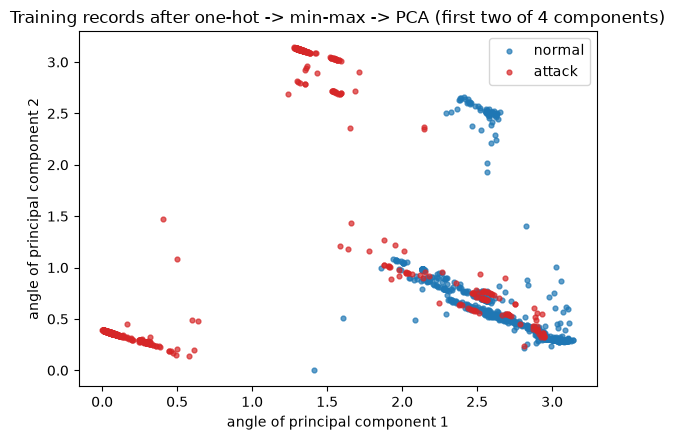

In [6]:
def prepare(X_tr_raw, X_te_raw, n_components, seed=SEED):
    """Fit one-hot -> min-max -> PCA -> angle scaling on the training split only; returns angle matrices in [0, pi]."""
    onehot = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS)],
                               remainder="passthrough")                       # paper: one-hot encoding
    pipe = make_pipeline(onehot, MinMaxScaler(), PCA(n_components=n_components, random_state=seed),   # paper: min-max, PCA
                         MinMaxScaler((0.0, np.pi)))                                                 # CHOICE: angles in [0, pi]
    A_tr = pipe.fit_transform(X_tr_raw)
    A_te = np.clip(pipe.transform(X_te_raw), 0.0, np.pi)
    return A_tr, A_te, pipe

A_train, A_test, prep_pipe = prepare(X_train_raw, X_test_raw, N_DATA_QUBITS)
ev = prep_pipe.named_steps["pca"].explained_variance_ratio_
print(f"{A_train.shape[1]} principal components keep {ev.sum():.1%} of the variance of the {prep_pipe.named_steps['pca'].n_features_in_} one-hot features (per component {np.round(ev, 3)})")
print("training angle matrix", A_train.shape, "| test", A_test.shape)

fig, ax = plt.subplots(figsize=(6, 4.5))
for cls, name, c in [(0, "normal", "tab:blue"), (1, "attack", "tab:red")]:
    m = y_train == cls
    ax.scatter(A_train[m, 0], A_train[m, 1], s=12, alpha=0.7, label=name, color=c)
ax.set_xlabel("angle of principal component 1"); ax.set_ylabel("angle of principal component 2")
ax.set_title("Training records after one-hot -> min-max -> PCA (first two of %d components)" % N_DATA_QUBITS); ax.legend()
plt.tight_layout(); plt.show()

## 4. Classical baselines on the raw PCA inputs

Before any quantum circuit runs, four classical models are trained on the 4 PCA angles that the QAE will receive, so
that the value added by the quantum pipeline can be measured against a fixed reference: a random forest and an RBF-SVM
(supervised, both classes), a kNN with $k$ chosen on the inner validation split, and a one-class SVM with an RBF kernel
(fitted on the normal training records only, $\nu$ and $\gamma$ chosen on the inner validation split). The same helpers are
reused in Section 11 for the paper's Table 4 counterparts on the QAE latent features.

In [7]:
METRICS = ["accuracy", "precision", "recall", "f1"]

def metrics(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, pos_label=ATTACK_POSITIVE, zero_division=0),
                recall=recall_score(y_true, y_pred, pos_label=ATTACK_POSITIVE, zero_division=0),
                f1=f1_score(y_true, y_pred, pos_label=ATTACK_POSITIVE, zero_division=0))

def ocsvm_predict(model, X_or_K):
    return (model.predict(X_or_K) == -1).astype(int)          # scikit-learn: -1 = outlier -> attack

def tune_rbf_ocsvm(X, y, seed=SEED):
    """CHOICE: nu and gamma by F1 on the inner validation split; the model itself only ever sees normal records."""
    itr, ival = inner_split(y, seed); normals = itr[y[itr] == 0]; best = None
    for g in GAMMA_GRID:
        for nu in NU_GRID:
            m = OneClassSVM(kernel="rbf", gamma=g, nu=nu).fit(X[normals])
            f = f1_score(y[ival], ocsvm_predict(m, X[ival]), zero_division=0)
            if best is None or f > best[0]:
                best = (f, g, nu)
    return OneClassSVM(kernel="rbf", gamma=best[1], nu=best[2]).fit(X[y == 0]), f"gamma={best[1]:g}, nu={best[2]:g}, inner-val F1 {best[0]:.3f}"

def tune_knn(X, y, seed=SEED):
    """CHOICE: k by F1 on the inner validation split."""
    itr, ival = inner_split(y, seed); best = None
    for k in K_GRID:
        f = f1_score(y[ival], KNeighborsClassifier(n_neighbors=k).fit(X[itr], y[itr]).predict(X[ival]), zero_division=0)
        if best is None or f > best[0]:
            best = (f, k)
    return KNeighborsClassifier(n_neighbors=best[1]).fit(X, y), f"k={best[1]}, inner-val F1 {best[0]:.3f}"

def classical_models(X, y, seed=SEED):
    """Four classical models fitted on (X, y); one-class SVM and kNN with tuned hyper-parameters."""
    out = {}
    t0 = time.perf_counter(); rf = RandomForestClassifier(n_estimators=200, random_state=seed).fit(X, y); out["RandomForest"] = (rf, "", time.perf_counter() - t0)
    t0 = time.perf_counter(); svc = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed).fit(X, y); out["SVC (rbf)"] = (svc, "C=1, gamma=scale", time.perf_counter() - t0)
    t0 = time.perf_counter(); knn, s = tune_knn(X, y, seed); out["kNN"] = (knn, s, time.perf_counter() - t0)
    t0 = time.perf_counter(); oc, s = tune_rbf_ocsvm(X, y, seed); out["OC-SVM (rbf)"] = (oc, s, time.perf_counter() - t0)
    return out

def evaluate_classical(X_tr, y_tr, X_te, y_te, inputs, seed=SEED):
    rows, preds = [], {}
    for name, (model, settings, t_fit) in classical_models(X_tr, y_tr, seed).items():
        t0 = time.perf_counter()
        pred = ocsvm_predict(model, X_te) if name.startswith("OC-SVM") else model.predict(X_te)
        rows.append(dict(model=name, inputs=inputs, fit_s=t_fit, predict_s=time.perf_counter() - t0, settings=settings, **metrics(y_te, pred)))
        preds[name] = pred
    return rows, preds

rows_pca, preds_pca = evaluate_classical(A_train, y_train, A_test, y_test, "PCA angles")
baseline_pca = pd.DataFrame(rows_pca)
display(baseline_pca.round(4))

,model,inputs,fit_s,predict_s,settings,accuracy,precision,recall,f1
0,RandomForest,PCA angles,0.9237,0.0540,,0.9817,0.9932,0.9700,0.9815
1,SVC (rbf),PCA angles,0.0538,0.0197,"C=1, gamma=scale",0.9567,1.0000,0.9133,0.9547
2,kNN,PCA angles,0.0768,0.0059,"k=5, inner-val F1 0.983",0.9817,0.9898,0.9733,0.9815
3,OC-SVM (rbf),PCA angles,0.5344,0.0040,"gamma=3, nu=0.01, inner-val F1 0.965",0.9817,0.9865,0.9767,0.9816


## 5. The quantum autoencoder circuit (Fig. 4 of the paper)

The QAE of Romero et al. (2017) as the paper builds it. The `N_DATA_QUBITS` data qubits are prepared by
`AngleEmbedding` from the PCA angles; a parameterised encoder $U(\theta)$ (`QAE_REPS` blocks of a layer of general
single-qubit rotations `Rot` followed by a chain of CNOTs between neighbouring qubits, then a final layer of rotations;
Fig. 4 of the paper shows one block, `QAE_REPS = 2` adds a second, see Section 6) is applied; after it the first
`N_LATENT` qubits hold the compressed state and the remaining `N_TRASH` qubits are the *trash*. A perfect encoder leaves
the trash in $|0\rangle$ for every normal input, which is tested by a **SWAP test** against `N_TRASH` reference qubits
prepared in $|0\rangle$: a Hadamard on an ancilla, a controlled-SWAP for each (reference, trash) pair, another Hadamard,
and the probability $p_0$ of measuring the ancilla in $|0\rangle$ gives the fidelity $F = 2 p_0 - 1$ between trash and
reference. The training cost is $1 - F$ averaged over the training batch (Eq. 1-4 of the paper). The decoder is not
needed for detection: it would be $U(\theta)^\dagger$ applied to latent + fresh $|0\rangle$ qubits.

The reference state is $|0\rangle$, so the SWAP-test fidelity equals the probability of reading $|0\ldots0\rangle$
directly on the trash qubits; the cell checks this identity numerically, and the QAE-as-feature-extractor later uses the
cheaper direct read-out. Which data qubits become trash is a choice: here the last ones, which carry the principal
components with the least variance.

QAE: 4 data qubits -> 2 latent + 2 trash | 2 reference qubits + 1 ancilla = 7 wires | 36 trainable angles
wire roles: ancilla 0 | reference [1, 2] | latent [3, 4] | trash [5, 6]


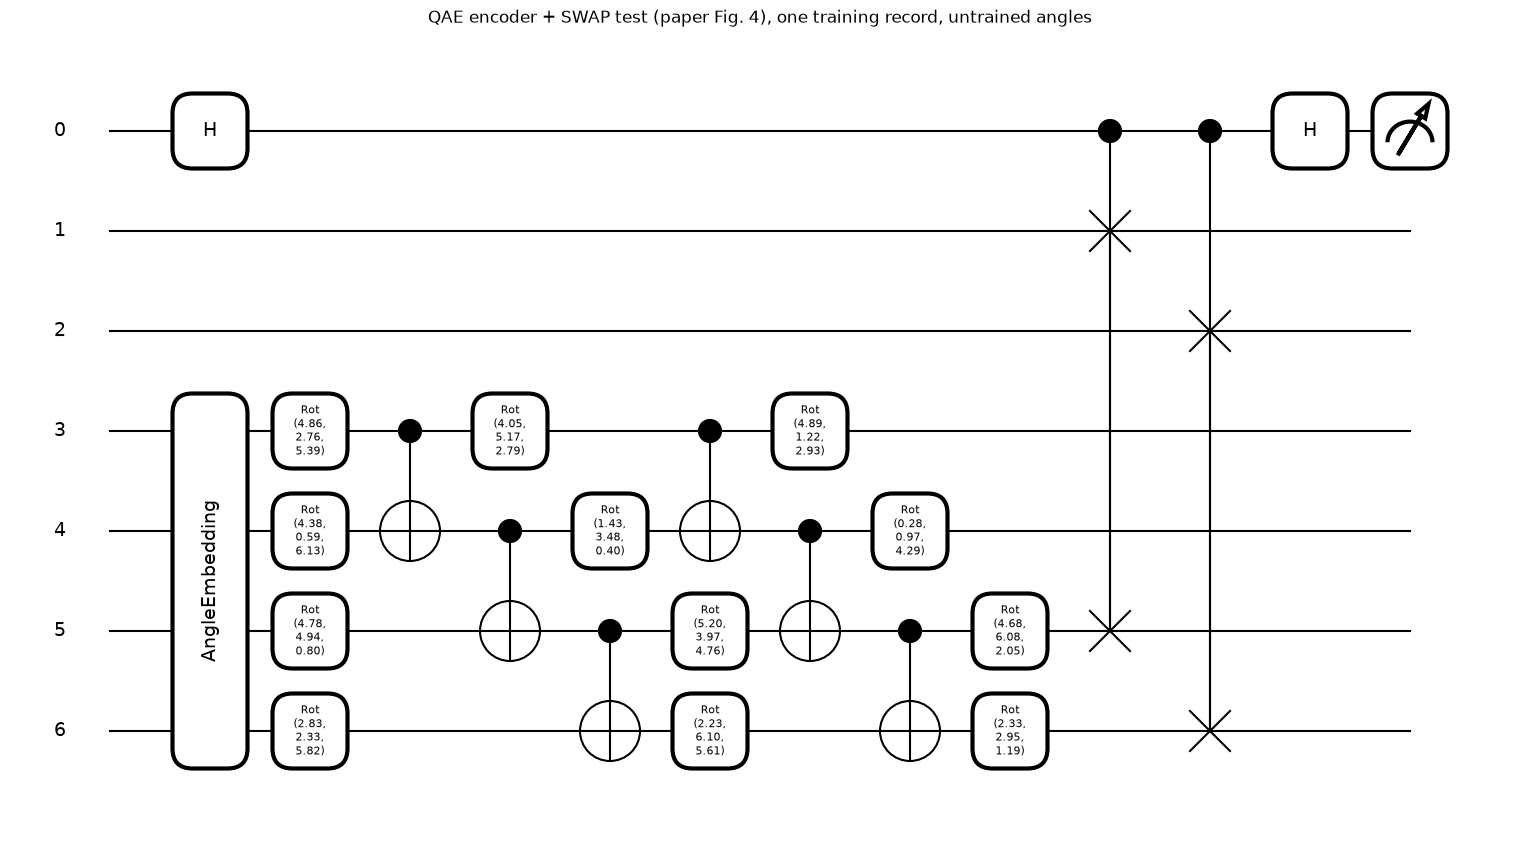

SWAP-test fidelity equals P(trash = |00>): True | first values [0.2767 0.2836 0.2603 0.4868]


In [8]:
def qae_layout(n_data, n_latent):
    n_trash = n_data - n_latent
    anc, ref = 0, list(range(1, 1 + n_trash))
    data = list(range(1 + n_trash, 1 + n_trash + n_data))
    return dict(anc=anc, ref=ref, data=data, latent=data[:n_latent], trash=data[n_latent:],   # CHOICE: trash = last data qubits
                n_wires=1 + n_trash + n_data, n_data=n_data, n_latent=n_latent, n_trash=n_trash)

def encoder(w, data, reps=QAE_REPS):
    """Fig. 4: rotation layer, CNOT chain, rotation layer (reps times the first two, then a final rotation layer)."""
    for r in range(reps):
        for i, q in enumerate(data):
            qml.Rot(w[r, i, 0], w[r, i, 1], w[r, i, 2], wires=q)
        for i in range(len(data) - 1):
            qml.CNOT(wires=[data[i], data[i + 1]])
    for i, q in enumerate(data):
        qml.Rot(w[reps, i, 0], w[reps, i, 1], w[reps, i, 2], wires=q)

def build_qae(n_data=N_DATA_QUBITS, n_latent=N_LATENT, reps=QAE_REPS):
    L = qae_layout(n_data, n_latent)
    dev = qml.device("default.qubit", wires=L["n_wires"])

    @qml.qnode(dev)
    def swap_test(x, w):                      # the paper's Fig. 4 circuit; x may be a batch (parameter broadcasting)
        qml.AngleEmbedding(x, wires=L["data"], rotation="Y")
        encoder(w, L["data"], reps)
        qml.Hadamard(wires=L["anc"])
        for r, t in zip(L["ref"], L["trash"]):
            qml.CSWAP(wires=[L["anc"], r, t])
        qml.Hadamard(wires=L["anc"])
        return qml.probs(wires=L["anc"])

    @qml.qnode(dev)
    def trash_probs(x, w):                    # direct read-out of the trash qubits (no ancilla needed)
        qml.AngleEmbedding(x, wires=L["data"], rotation="Y")
        encoder(w, L["data"], reps)
        return qml.probs(wires=L["trash"])

    @qml.qnode(dev)
    def latent_expvals(x, w):                 # classical latent features: <Z> and <X> of every latent qubit
        qml.AngleEmbedding(x, wires=L["data"], rotation="Y")
        encoder(w, L["data"], reps)
        obs = {"Z": qml.PauliZ, "X": qml.PauliX, "Y": qml.PauliY}
        return [qml.expval(obs[o](q)) for o in LATENT_OBS for q in L["latent"]]

    return dict(layout=L, swap_test=swap_test, trash_probs=trash_probs, latent_expvals=latent_expvals,
                shape=(reps + 1, n_data, 3))

def swap_fidelity(qae, w, X, chunk=256):
    """F = 2 p0 - 1 from the SWAP test, for every row of X."""
    out = [2.0 * np.asarray(qae["swap_test"](X[s:s + chunk], w))[:, 0] - 1.0 for s in range(0, len(X), chunk)]
    return np.concatenate(out)

def trash_fidelity(qae, w, X, chunk=256):
    """P(trash = |0...0>) = the same fidelity, read directly."""
    return np.concatenate([np.asarray(qae["trash_probs"](X[s:s + chunk], w))[:, 0] for s in range(0, len(X), chunk)])

qae = build_qae()
L = qae["layout"]
w_demo = pnp.array(rng.uniform(0, 2 * np.pi, qae["shape"]), requires_grad=False)
print(f"QAE: {L['n_data']} data qubits -> {L['n_latent']} latent + {L['n_trash']} trash | {L['n_trash']} reference qubits + 1 ancilla = {L['n_wires']} wires | "
      f"{int(np.prod(qae['shape']))} trainable angles")
print("wire roles: ancilla", L["anc"], "| reference", L["ref"], "| latent", L["latent"], "| trash", L["trash"])
fig, ax = qml.draw_mpl(qae["swap_test"], decimals=2)(A_train[0], w_demo)
ax.set_title("QAE encoder + SWAP test (paper Fig. 4), one training record, untrained angles"); plt.show()

f_swap, f_direct = swap_fidelity(qae, w_demo, A_train[:16]), trash_fidelity(qae, w_demo, A_train[:16])
print("SWAP-test fidelity equals P(trash = |00>):", np.allclose(f_swap, f_direct, atol=1e-8), "| first values", np.round(f_swap[:4], 4))

## 6. Training the QAE on normal connections

The encoder angles are optimised with Adam on mini-batches of the **normal** training records; the cost is the mean of
$1 - F$ from the SWAP test (PennyLane's autograd differentiates through the simulated circuit). The paper optimised with
PyTorch and reports hours of training per QAE (Table 2) because every record was a separate circuit evaluation; here
PennyLane's parameter broadcasting simulates a whole batch in one call.

After training, the fidelity is reported on the training normals (the paper's "fidelity" column of Table 2), on the
test normals and on the test attacks. The gap between the last two is what makes the QAE useful for anomaly detection:
attacks were never seen, so their trash qubits are not driven to $|0\rangle$. Finally the paper's Table 2 sweep is
re-measured: a QAE with (2, 1), (4, 2), (4, 3) and (6, 4) (data, latent) qubits is trained with `SWEEP_EPOCHS` epochs each
and the time and fidelity recorded. The first row is the literal 4-wire circuit of Fig. 4 (2 data qubits, 1 latent,
one encoder block); the second row is the paper's "4 qubits, 2 latent" with the single block of Fig. 4, whose cost
flattens at $1 - F \approx 0.19$ after a few epochs: one rotation-CNOT block cannot disentangle two of four qubits for
this data, which is why the notebook's default encoder has two blocks (`QAE_REPS = 2`, third row and the main run
above). The sweep rows are trained for only `SWEEP_EPOCHS` epochs from a single random start, so a two-block row can
sit on the same plateau as the one-block row; the main run above is the number to compare with Table 2.

epoch   1/100: mean (1 - fidelity) = 0.4206


epoch  11/100: mean (1 - fidelity) = 0.1009


epoch  21/100: mean (1 - fidelity) = 0.0960


epoch  31/100: mean (1 - fidelity) = 0.0957


epoch  41/100: mean (1 - fidelity) = 0.0962


...

epoch  61/100: mean (1 - fidelity) = 0.0951


epoch  71/100: mean (1 - fidelity) = 0.0952


epoch  81/100: mean (1 - fidelity) = 0.0953


epoch  91/100: mean (1 - fidelity) = 0.0952


epoch 100/100: mean (1 - fidelity) = 0.0944
QAE trained in 190 s on 1200 normal records | fidelity: training normals 0.9055, test normals 0.8822, test attacks 0.2946


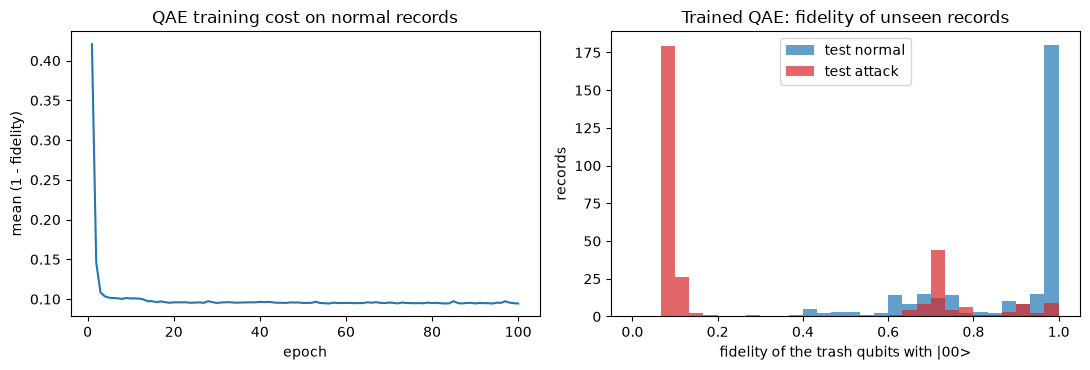

{'data_qubits': 2, 'latent_qubits': 1, 'trash_qubits': 1, 'wires': 4, 'encoder_blocks': 1, 'angles': 12, 'epochs': 40, 'time_s': 21.5, 'fidelity_train_normal': 0.9518, 'fidelity_test_normal': 0.952, 'fidelity_test_attack': 0.7853}


{'data_qubits': 4, 'latent_qubits': 2, 'trash_qubits': 2, 'wires': 7, 'encoder_blocks': 1, 'angles': 24, 'epochs': 40, 'time_s': 52.8, 'fidelity_train_normal': 0.8118, 'fidelity_test_normal': 0.7907, 'fidelity_test_attack': 0.9496}


{'data_qubits': 4, 'latent_qubits': 2, 'trash_qubits': 2, 'wires': 7, 'encoder_blocks': 2, 'angles': 36, 'epochs': 40, 'time_s': 52.6, 'fidelity_train_normal': 0.9041, 'fidelity_test_normal': 0.8807, 'fidelity_test_attack': 0.3035}


{'data_qubits': 4, 'latent_qubits': 3, 'trash_qubits': 1, 'wires': 6, 'encoder_blocks': 2, 'angles': 36, 'epochs': 40, 'time_s': 46.8, 'fidelity_train_normal': 0.991, 'fidelity_test_normal': 0.9909, 'fidelity_test_attack': 0.3218}


{'data_qubits': 6, 'latent_qubits': 4, 'trash_qubits': 2, 'wires': 9, 'encoder_blocks': 2, 'angles': 54, 'epochs': 40, 'time_s': 156.3, 'fidelity_train_normal': 0.9246, 'fidelity_test_normal': 0.9246, 'fidelity_test_attack': 0.3679}

This notebook's version of Table 2 (paper: 4/2 -> 1.64 h, F = 0.9963; 4/3 -> 1.49 h, F = 0.9812; 6/4 -> 7.85 h, F = 0.8610):


,data_qubits,latent_qubits,trash_qubits,wires,encoder_blocks,angles,epochs,time_s,fidelity_train_normal,fidelity_test_normal,fidelity_test_attack
0,2,1,1,4,1,12,40,21.5,0.9518,0.9520,0.7853
1,4,2,2,7,1,24,40,52.8,0.8118,0.7907,0.9496
2,4,2,2,7,2,36,40,52.6,0.9041,0.8807,0.3035
3,4,3,1,6,2,36,40,46.8,0.9910,0.9909,0.3218
4,6,4,2,9,2,54,40,156.3,0.9246,0.9246,0.3679


In [9]:
def train_qae(qae, X_normal, epochs=QAE_EPOCHS, batch=QAE_BATCH, lr=QAE_LR, seed=SEED, verbose=True):
    r = np.random.default_rng(seed)
    w = pnp.array(r.uniform(0, 2 * np.pi, qae["shape"]), requires_grad=True)       # CHOICE: uniform random initial angles
    opt = qml.AdamOptimizer(stepsize=lr)
    def cost(ww, xb):
        p = qae["swap_test"](xb, ww)
        return pnp.mean(1.0 - (2.0 * p[:, 0] - 1.0))                                # mean (1 - fidelity), Eq. 1-4
    history = []
    for ep in range(epochs):
        perm = r.permutation(len(X_normal)); losses = []
        for s in range(0, len(X_normal), batch):
            xb = pnp.array(X_normal[perm[s:s + batch]], requires_grad=False)
            w, c = opt.step_and_cost(lambda ww: cost(ww, xb), w); losses.append(float(c))
        history.append(float(np.mean(losses)))
        if verbose and (ep % max(1, epochs // 10) == 0 or ep == epochs - 1):
            print(f"epoch {ep + 1:3d}/{epochs}: mean (1 - fidelity) = {history[-1]:.4f}")
    return np.asarray(w), history

X_normal_train = A_train[y_train == 0]
t0 = time.perf_counter()
w_qae, qae_history = train_qae(qae, X_normal_train)
t_qae = time.perf_counter() - t0
fid_train_normal = trash_fidelity(qae, w_qae, X_normal_train)
fid_test = trash_fidelity(qae, w_qae, A_test)
print(f"QAE trained in {t_qae:.0f} s on {len(X_normal_train)} normal records | fidelity: training normals {fid_train_normal.mean():.4f}, "
      f"test normals {fid_test[y_test == 0].mean():.4f}, test attacks {fid_test[y_test == 1].mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(np.arange(1, len(qae_history) + 1), qae_history); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("mean (1 - fidelity)")
axes[0].set_title("QAE training cost on normal records")
axes[1].hist(fid_test[y_test == 0], bins=30, range=(0, 1), alpha=0.7, label="test normal", color="tab:blue")
axes[1].hist(fid_test[y_test == 1], bins=30, range=(0, 1), alpha=0.7, label="test attack", color="tab:red")
axes[1].set_xlabel("fidelity of the trash qubits with |00>"); axes[1].set_ylabel("records"); axes[1].legend()
axes[1].set_title("Trained QAE: fidelity of unseen records")
plt.tight_layout(); plt.show()

# Table 2 of the paper: fidelity and training time versus the number of qubits (same epochs for every row)
sweep_rows = []
for n_data, n_latent, reps_s in QAE_SWEEP:
    A_tr_s, A_te_s, _ = prepare(X_train_raw, X_test_raw, n_data)
    q_s = build_qae(n_data, n_latent, reps_s)
    t0 = time.perf_counter(); w_s, h_s = train_qae(q_s, A_tr_s[y_train == 0], epochs=SWEEP_EPOCHS, verbose=False); t_s = time.perf_counter() - t0
    sweep_rows.append(dict(data_qubits=n_data, latent_qubits=n_latent, trash_qubits=n_data - n_latent, wires=q_s["layout"]["n_wires"], encoder_blocks=reps_s,
                           angles=int(np.prod(q_s["shape"])), epochs=SWEEP_EPOCHS, time_s=round(t_s, 1),
                           fidelity_train_normal=round(float(trash_fidelity(q_s, w_s, A_tr_s[y_train == 0]).mean()), 4),
                           fidelity_test_normal=round(float(trash_fidelity(q_s, w_s, A_te_s[y_test == 0]).mean()), 4),
                           fidelity_test_attack=round(float(trash_fidelity(q_s, w_s, A_te_s[y_test == 1]).mean()), 4)))
    print(sweep_rows[-1])
sweep_df = pd.DataFrame(sweep_rows)
print("\nThis notebook's version of Table 2 (paper: 4/2 -> 1.64 h, F = 0.9963; 4/3 -> 1.49 h, F = 0.9812; 6/4 -> 7.85 h, F = 0.8610):")
display(sweep_df)

## 7. The naive detector and the QAE latent features

**Naive detector (Section 4 of the paper).** The simplest use of a trained autoencoder is to call a record anomalous
when its reconstruction is poor; for the QAE that is a low trash fidelity. The threshold is chosen on the inner validation
split (best F1), then applied to the test split. The paper reports that this scored only 75 % accuracy / 77 % F1 and
motivates the three frameworks with it. The rule assumes that attacks get a *lower* fidelity than normal records; the
histogram of Section 6 shows whether that holds for the current draw (a DoS flood is a very regular record, and a QAE
trained on normal traffic sometimes compresses it just as well, in which case the rule fails).

**Latent features.** The three frameworks need the compressed state as classical input for the next circuit. The paper
says the latent subsystem is "measured"; a single measurement of two qubits would give only two bits, so the notebook
reads the expectation values $\langle Z\rangle$ and $\langle X\rangle$ of each latent qubit (four numbers for two latent
qubits, `LATENT_OBS`) and min-max scales them to $[0, \pi]$ on the training split. Those four numbers are the input of
Frameworks 1-3 and of the classical counterparts of Table 4.

naive reconstruction-error detector: threshold fidelity < 0.9332 (inner-val F1 0.877) -> test accuracy 0.807, F1 0.833 (paper: 0.75 / 0.77)


latent feature matrices: (2400, 4) (600, 4) | features: ['<Z> q3', '<Z> q4', '<X> q3', '<X> q4']


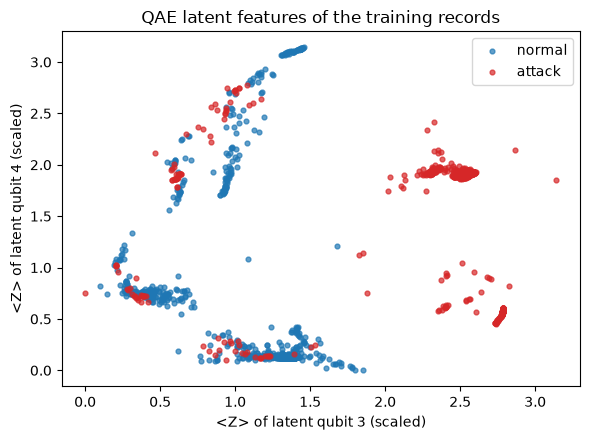

In [10]:
def naive_detector(fid_tr, y_tr, fid_te, seed=SEED):
    """Anomaly score = 1 - fidelity; threshold chosen by F1 on the inner validation split (CHOICE)."""
    itr, ival = inner_split(y_tr, seed)
    cands = np.unique(np.quantile(fid_tr[ival], np.linspace(0.01, 0.99, 99)))
    best = max(((f1_score(y_tr[ival], (fid_tr[ival] < t).astype(int), zero_division=0), t) for t in cands), key=lambda z: z[0])
    return (fid_te < best[1]).astype(int), dict(threshold=float(best[1]), val_f1=float(best[0]))

def latent_features(qae, w, X, chunk=256):
    return np.vstack([np.asarray(qae["latent_expvals"](X[s:s + chunk], w)).T for s in range(0, len(X), chunk)])

fid_train = trash_fidelity(qae, w_qae, A_train)
pred_naive, naive_info = naive_detector(fid_train, y_train, fid_test)
m_naive = metrics(y_test, pred_naive)
print(f"naive reconstruction-error detector: threshold fidelity < {naive_info['threshold']:.4f} (inner-val F1 {naive_info['val_f1']:.3f}) -> "
      f"test accuracy {m_naive['accuracy']:.3f}, F1 {m_naive['f1']:.3f} (paper: 0.75 / 0.77)")

latent_scaler = MinMaxScaler((0.0, np.pi)).fit(latent_features(qae, w_qae, A_train))      # fitted on the training split only
L_train = latent_scaler.transform(latent_features(qae, w_qae, A_train))
L_test = np.clip(latent_scaler.transform(latent_features(qae, w_qae, A_test)), 0.0, np.pi)
N_LATENT_FEATURES = L_train.shape[1]
print("latent feature matrices:", L_train.shape, L_test.shape, "| features:", [f"<{o}> q{q}" for o in LATENT_OBS for q in L["latent"]])

fig, ax = plt.subplots(figsize=(6, 4.5))
for cls, name, c in [(0, "normal", "tab:blue"), (1, "attack", "tab:red")]:
    m = y_train == cls
    ax.scatter(L_train[m, 0], L_train[m, 1], s=12, alpha=0.7, label=name, color=c)
ax.set_xlabel("<Z> of latent qubit %d (scaled)" % L["latent"][0]); ax.set_ylabel("<Z> of latent qubit %d (scaled)" % L["latent"][1])
ax.set_title("QAE latent features of the training records"); ax.legend(); plt.tight_layout(); plt.show()

## 8. Framework 1: QAE + one-class SVM with a quantum kernel (Fig. 3a, Fig. 5)

The latent features are encoded by Qiskit's `zz_feature_map` (a Hadamard layer, Z rotations by the features, ZZ
couplings between all qubit pairs; `reps = 1` as in the paper's Fig. 5). The kernel value of two records is the fidelity
$|\langle\Phi(a)|\Phi(b)\rangle|^2$, computed exactly by `FidelityStatevectorKernel` (the paper's `QuantumKernel` on
`ibmq_lima` estimated the same quantity with shots). The kernel matrix among the **normal** training records is handed to
scikit-learn's `OneClassSVM(kernel="precomputed")`; a test record is an anomaly when it falls outside the learned
boundary.

Two settings the paper does not give are chosen on the inner validation split: the angle bandwidth `scale` (the ZZ
terms $(\pi - x_i)(\pi - x_j)$ make the kernel very sharp for angles up to $\pi$) and $\nu$, the upper bound on the
fraction of normal training records treated as outliers. The kernel is cross-checked by hand on a few records.

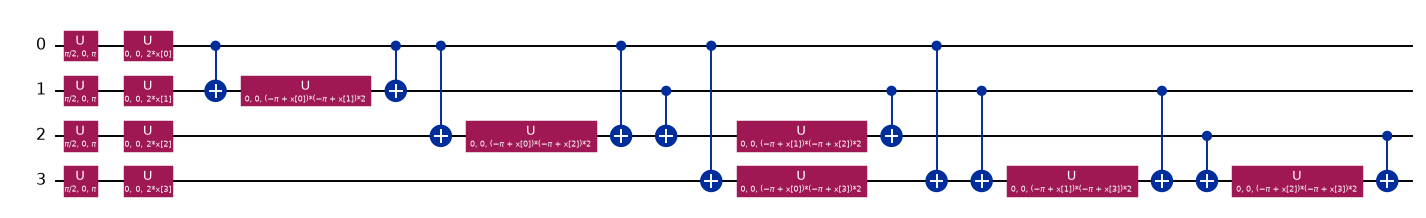

Framework 1: scale 0.25, nu 0.01 (inner-val F1 0.950) | 212.3 s incl. tuning | test accuracy 0.950 precision 0.979 recall 0.920 F1 0.948
hand-computed |<Phi(a)|Phi(b)>|^2 matches FidelityStatevectorKernel: True


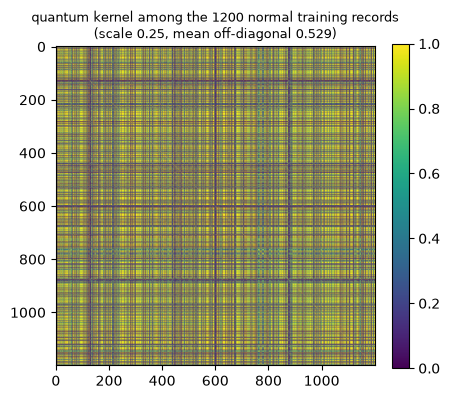

In [11]:
fm_kernel = zz_feature_map(N_LATENT_FEATURES, reps=FM_REPS)        # paper Fig. 5 (entanglement "full": "ZZ gates across all the qubits")
qkernel = FidelityStatevectorKernel(feature_map=fm_kernel)
display(fm_kernel.decompose().draw("mpl", fold=-1, scale=0.7))

def framework1(L_tr, y_tr, L_te, seed=SEED):
    itr, ival = inner_split(y_tr, seed); normals_in = itr[y_tr[itr] == 0]; best, cache = None, {}
    for scale in SCALE_GRID:
        K = qkernel.evaluate(scale * L_tr); cache[scale] = K
        for nu in NU_GRID:
            m = OneClassSVM(kernel="precomputed", nu=nu).fit(K[np.ix_(normals_in, normals_in)])
            f = f1_score(y_tr[ival], ocsvm_predict(m, K[np.ix_(ival, normals_in)]), zero_division=0)
            if best is None or f > best[0]:
                best = (f, scale, nu)
    f, scale, nu = best; normals = np.where(y_tr == 0)[0]
    K_tr = cache[scale][np.ix_(normals, normals)]
    t0 = time.perf_counter(); model = OneClassSVM(kernel="precomputed", nu=nu).fit(K_tr); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); K_te = qkernel.evaluate(scale * L_te, scale * L_tr[normals]); pred = ocsvm_predict(model, K_te); t_pred = time.perf_counter() - t0
    return pred, dict(scale=scale, nu=nu, val_f1=f, fit_s=t_fit, predict_s=t_pred, K_train=K_tr, K_test=K_te)

t0 = time.perf_counter()
pred_f1, info_f1 = framework1(L_train, y_train, L_test)
t_f1 = time.perf_counter() - t0
m_f1 = metrics(y_test, pred_f1)
print(f"Framework 1: scale {info_f1['scale']}, nu {info_f1['nu']} (inner-val F1 {info_f1['val_f1']:.3f}) | {t_f1:.1f} s incl. tuning | "
      f"test accuracy {m_f1['accuracy']:.3f} precision {m_f1['precision']:.3f} recall {m_f1['recall']:.3f} F1 {m_f1['f1']:.3f}")

# hand check of the kernel on a few training records
sv = [Statevector(fm_kernel.assign_parameters(info_f1["scale"] * x)) for x in L_train[:8]]
K_hand = np.abs(np.array([[a.inner(b) for b in sv] for a in sv])) ** 2
print("hand-computed |<Phi(a)|Phi(b)>|^2 matches FidelityStatevectorKernel:", np.allclose(K_hand, qkernel.evaluate(info_f1["scale"] * L_train[:8]), atol=1e-8))

fig, ax = plt.subplots(figsize=(4.6, 4.2))
im = ax.imshow(info_f1["K_train"], cmap="viridis", vmin=0, vmax=1); plt.colorbar(im, fraction=0.046)
ax.set_title(f"quantum kernel among the {len(info_f1['K_train'])} normal training records\n(scale {info_f1['scale']}, mean off-diagonal {info_f1['K_train'][~np.eye(len(info_f1['K_train']), dtype=bool)].mean():.3f})", fontsize=9)
plt.tight_layout(); plt.show()

## 9. Framework 2: QAE + "quantum random forest" (Fig. 3b, Fig. 6)

The paper's quantum random forest is a bagging ensemble of variational quantum classifiers: each "tree" is a VQC
(`zz_feature_map` + `real_amplitudes` ansatz, Fig. 6: a layer of RY rotations and a CNOT chain, repeated) trained with
COBYLA on its own bootstrap sample of the training records; the forest predicts by majority vote. Unlike Framework 1 this
is a supervised classifier, so the bootstrap samples contain both classes (drawn class-stratified so that no tree sees a
single class). Qiskit's `VQC` measures all qubits and maps bit-string parity to the class; the sampler uses `SHOTS` shots
with a fixed seed. The training loss of every tree is recorded and plotted.

one tree: 4 input angles, 12 trainable angles


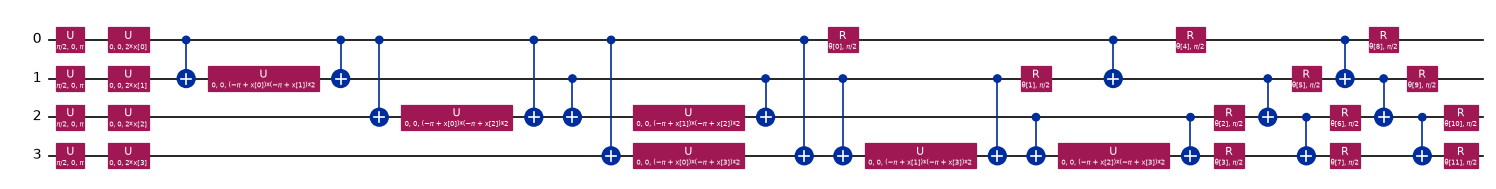

tree 1/5: 150 bootstrap rows, final loss 0.7832, 109 s, train acc 0.860


tree 2/5: 150 bootstrap rows, final loss 0.8287, 97 s, train acc 0.787


tree 3/5: 150 bootstrap rows, final loss 0.7990, 99 s, train acc 0.860


tree 4/5: 150 bootstrap rows, final loss 0.8188, 72 s, train acc 0.827


tree 5/5: 150 bootstrap rows, final loss 0.7931, 104 s, train acc 0.847
Framework 2: 5 trees, 503 s | test accuracy 0.818 precision 0.789 recall 0.870 F1 0.827 | single trees: 0.807, 0.750, 0.775, 0.722, 0.813


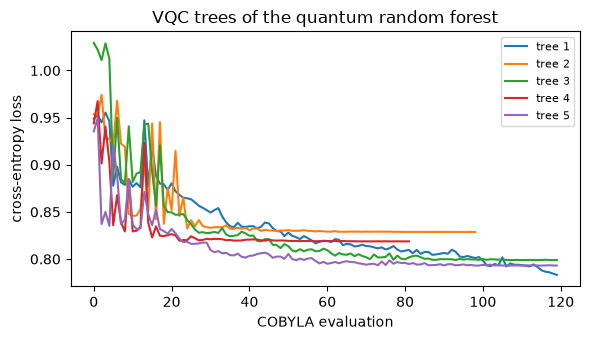

In [12]:
fm_tree = zz_feature_map(N_LATENT_FEATURES, reps=FM_REPS)
ansatz_tree = real_amplitudes(N_LATENT_FEATURES, reps=QRF_ANSATZ_REPS, entanglement="linear")   # Fig. 6: RY layer + CNOT chain
print("one tree:", fm_tree.num_parameters, "input angles,", ansatz_tree.num_parameters, "trainable angles")
display(fm_tree.compose(ansatz_tree).decompose().draw("mpl", fold=-1, scale=0.6))

def framework2(L_tr, y_tr, L_te, seed=SEED, n_trees=QRF_TREES, n_boot=QRF_BOOTSTRAP, maxiter=QRF_MAXITER, verbose=True):
    r = np.random.default_rng(seed); tree_preds, histories, times = [], [], []
    for t in range(n_trees):
        idx = np.concatenate([r.choice(np.where(y_tr == c)[0], size=n_boot // 2, replace=True) for c in (0, 1)])   # CHOICE: class-stratified bootstrap
        algorithm_globals.random_seed = seed + t                                  # different initial angles per tree
        hist = []
        vqc = VQC(feature_map=fm_tree, ansatz=ansatz_tree, optimizer=COBYLA(maxiter=maxiter),
                  sampler=AerSampler(default_shots=SHOTS, seed=seed + t), callback=lambda w, loss: hist.append(loss))
        t0 = time.perf_counter(); vqc.fit(L_tr[idx], y_tr[idx]); times.append(time.perf_counter() - t0)
        tree_preds.append(np.asarray(vqc.predict(L_te)).astype(int).ravel()); histories.append(hist)
        if verbose:
            print(f"tree {t + 1}/{n_trees}: {len(idx)} bootstrap rows, final loss {hist[-1]:.4f}, {times[-1]:.0f} s, "
                  f"train acc {accuracy_score(y_tr[idx], vqc.predict(L_tr[idx])):.3f}")
    votes = np.mean(tree_preds, axis=0)
    return (votes > 0.5).astype(int), dict(tree_preds=tree_preds, histories=histories, times=times)

t0 = time.perf_counter()
pred_f2, info_f2 = framework2(L_train, y_train, L_test)
t_f2 = time.perf_counter() - t0
m_f2 = metrics(y_test, pred_f2)
print(f"Framework 2: {QRF_TREES} trees, {t_f2:.0f} s | test accuracy {m_f2['accuracy']:.3f} precision {m_f2['precision']:.3f} "
      f"recall {m_f2['recall']:.3f} F1 {m_f2['f1']:.3f} | single trees: " + ", ".join(f"{accuracy_score(y_test, p):.3f}" for p in info_f2["tree_preds"]))
fig, ax = plt.subplots(figsize=(6, 3.5))
for t, h in enumerate(info_f2["histories"]):
    ax.plot(h, label=f"tree {t + 1}")
ax.set_xlabel("COBYLA evaluation"); ax.set_ylabel("cross-entropy loss"); ax.set_title("VQC trees of the quantum random forest"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 10. Framework 3: QAE + quantum k-nearest neighbours (Fig. 3c, Fig. 7)

Each latent feature vector is encoded as a quantum state (`KNN_ENCODING = "angle"`: one RY-rotated qubit per feature;
`"amplitude"`: the four features as amplitudes of two qubits). The similarity between a test state and a training state
is the fidelity $|\langle\phi_a|\phi_b\rangle|^2$, which a quantum computer estimates with the SWAP test of Fig. 7 (ancilla
Hadamard, controlled-SWAPs between the two registers, Hadamard, measure the ancilla). The notebook computes all
test-by-training fidelities exactly from statevectors, then runs the real SWAP-test circuit with `SHOTS` shots on one pair
to show that it estimates the same number. The $k$ most similar training records vote; $k$ is chosen on the inner
validation split.

Framework 3: k = 3 (inner-val F1 0.977), 4 qubits per register, 0.8 s | test accuracy 0.973 precision 0.983 recall 0.963 F1 0.973
SWAP test with 1024 shots: fidelity estimate 1.0000 vs exact 1.0000 (test record 0 and its nearest training record 810)


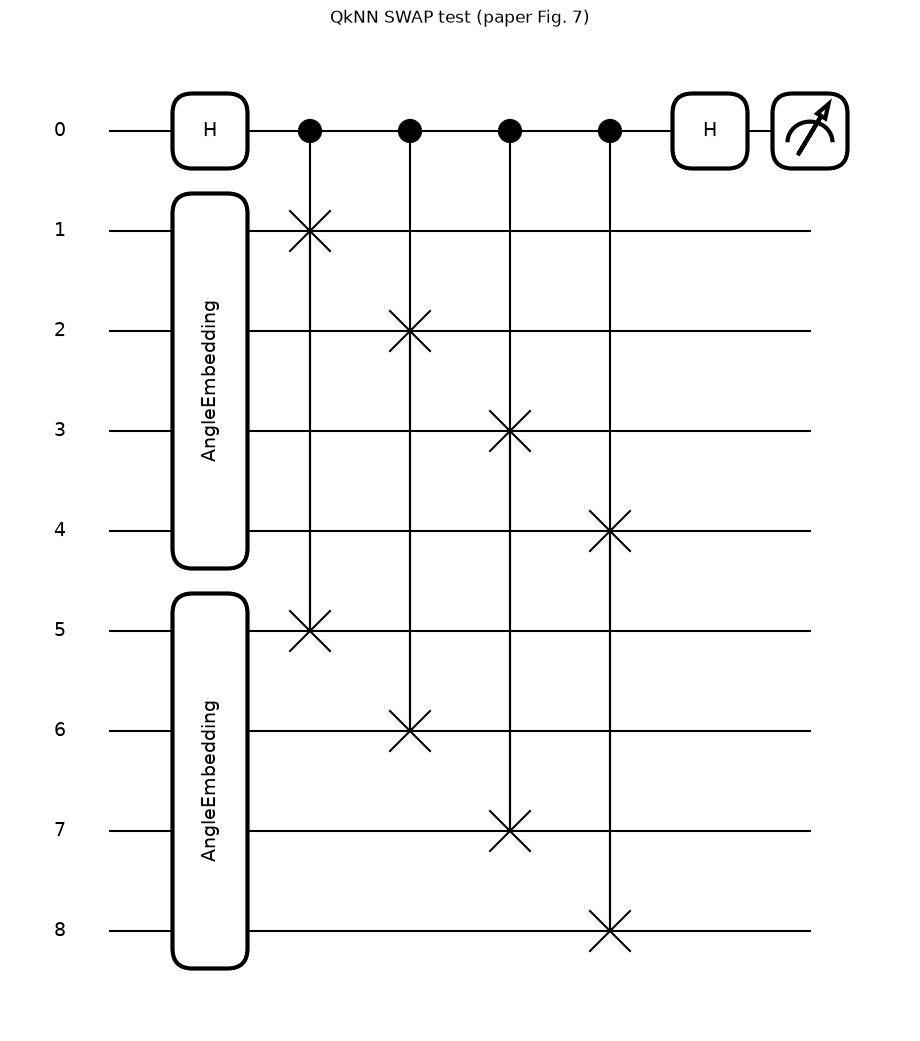

In [13]:
if KNN_ENCODING == "amplitude":
    N_KNN_QUBITS = int(math.ceil(math.log2(N_LATENT_FEATURES)))
else:
    N_KNN_QUBITS = N_LATENT_FEATURES
dev_knn = qml.device("default.qubit", wires=N_KNN_QUBITS)

def knn_embed(x, wires):
    if KNN_ENCODING == "amplitude":
        qml.AmplitudeEmbedding(x, wires=wires, normalize=True, pad_with=0.0)
    else:
        qml.AngleEmbedding(x, wires=wires, rotation="Y")

@qml.qnode(dev_knn)
def knn_state(x):
    knn_embed(x, list(range(N_KNN_QUBITS)))
    return qml.state()

def knn_states(X, chunk=256):
    return np.vstack([np.asarray(knn_state(X[s:s + chunk])).reshape(len(X[s:s + chunk]), -1) for s in range(0, len(X), chunk)])

def fidelity_matrix(SA, SB):
    return np.abs(SA @ SB.conj().T) ** 2

def qknn_vote(F, y_ref, k):
    nn = np.argsort(-F, axis=1)[:, :k]                       # k most similar training states
    return (y_ref[nn].mean(axis=1) > 0.5).astype(int)        # majority vote (k odd -> no ties)

def framework3(L_tr, y_tr, L_te, seed=SEED):
    itr, ival = inner_split(y_tr, seed)
    t0 = time.perf_counter(); S_tr = knn_states(L_tr); F_tr = fidelity_matrix(S_tr, S_tr); t_states = time.perf_counter() - t0
    best = max(((f1_score(y_tr[ival], qknn_vote(F_tr[np.ix_(ival, itr)], y_tr[itr], k), zero_division=0), k) for k in K_GRID), key=lambda z: z[0])
    t0 = time.perf_counter(); F_te = fidelity_matrix(knn_states(L_te), S_tr); pred = qknn_vote(F_te, y_tr, best[1]); t_pred = time.perf_counter() - t0
    return pred, dict(k=best[1], val_f1=best[0], states_s=t_states, predict_s=t_pred, F_test=F_te)

t0 = time.perf_counter()
pred_f3, info_f3 = framework3(L_train, y_train, L_test)
t_f3 = time.perf_counter() - t0
m_f3 = metrics(y_test, pred_f3)
print(f"Framework 3: k = {info_f3['k']} (inner-val F1 {info_f3['val_f1']:.3f}), {N_KNN_QUBITS} qubits per register, {t_f3:.1f} s | "
      f"test accuracy {m_f3['accuracy']:.3f} precision {m_f3['precision']:.3f} recall {m_f3['recall']:.3f} F1 {m_f3['f1']:.3f}")

# the paper's Fig. 7: SWAP test between one test state and its most similar training state, with shots
dev_swap = qml.device("default.qubit", wires=2 * N_KNN_QUBITS + 1, shots=SHOTS, seed=SEED)
@qml.qnode(dev_swap)
def knn_swap_test(a, b):
    knn_embed(a, list(range(1, N_KNN_QUBITS + 1)))
    knn_embed(b, list(range(N_KNN_QUBITS + 1, 2 * N_KNN_QUBITS + 1)))
    qml.Hadamard(wires=0)
    for i in range(N_KNN_QUBITS):
        qml.CSWAP(wires=[0, 1 + i, N_KNN_QUBITS + 1 + i])
    qml.Hadamard(wires=0)
    return qml.probs(wires=0)
j = int(np.argmax(info_f3["F_test"][0]))
F_est = 2 * knn_swap_test(L_test[0], L_train[j])[0] - 1
print(f"SWAP test with {SHOTS} shots: fidelity estimate {F_est:.4f} vs exact {info_f3['F_test'][0, j]:.4f} (test record 0 and its nearest training record {j})")
fig, ax = qml.draw_mpl(knn_swap_test, decimals=2)(L_test[0], L_train[j])
ax.set_title("QkNN SWAP test (paper Fig. 7)"); plt.show()

## 11. Classical counterparts on the QAE latent features (Table 4), metrics and confusion matrices

The paper's Table 4 trains a one-class SVM, a random forest and a kNN "with the same data preprocessing steps" and finds
every quantum framework ahead of its classical counterpart. Here the same three models (plus an RBF-SVM) are trained on
exactly the QAE latent features that the frameworks use, with the same inner-validation tuning. Then all models are
collected in one table with their timings, the confusion matrices of the three frameworks are drawn, and the recall is
broken down by attack family (a DoS flood and a password-guessing attack are not equally hard to spot).

QAE training time (shared by every 'QAE latent' model): 190 s


,model,inputs,accuracy,precision,recall,f1,fit_s,predict_s,settings
0,Framework 1: QAE + quantum-kernel OC-SVM,QAE latent,0.9500,0.9787,0.9200,0.9485,0.0031,13.3163,"scale=0.25, nu=0.01"
1,Framework 2: QAE + quantum random forest,QAE latent,0.8183,0.7885,0.8700,0.8273,480.2982,NaN,"5 trees x 150 rows, COBYLA 120"
2,Framework 3: QAE + quantum kNN,QAE latent,0.9733,0.9830,0.9633,0.9731,0.2436,0.1345,"k=3, angle encoding"
3,Naive: QAE reconstruction error,QAE fidelity,0.8067,0.7335,0.9633,0.8329,189.8705,NaN,fidelity < 0.933
4,RandomForest,QAE latent,0.9733,0.9897,0.9567,0.9729,0.7518,0.0214,
5,SVC (rbf),QAE latent,0.9533,1.0000,0.9067,0.9510,0.0376,0.0118,"C=1, gamma=scale"
6,kNN,QAE latent,0.9733,0.9830,0.9633,0.9731,0.0423,0.0034,"k=3, inner-val F1 0.977"
7,OC-SVM (rbf),QAE latent,0.9617,0.9727,0.9500,0.9612,0.2709,0.0031,"gamma=3, nu=0.01, inner-val F1 0.953"
8,RandomForest,PCA angles,0.9817,0.9932,0.9700,0.9815,0.9237,0.0540,
9,SVC (rbf),PCA angles,0.9567,1.0000,0.9133,0.9547,0.0538,0.0197,"C=1, gamma=scale"


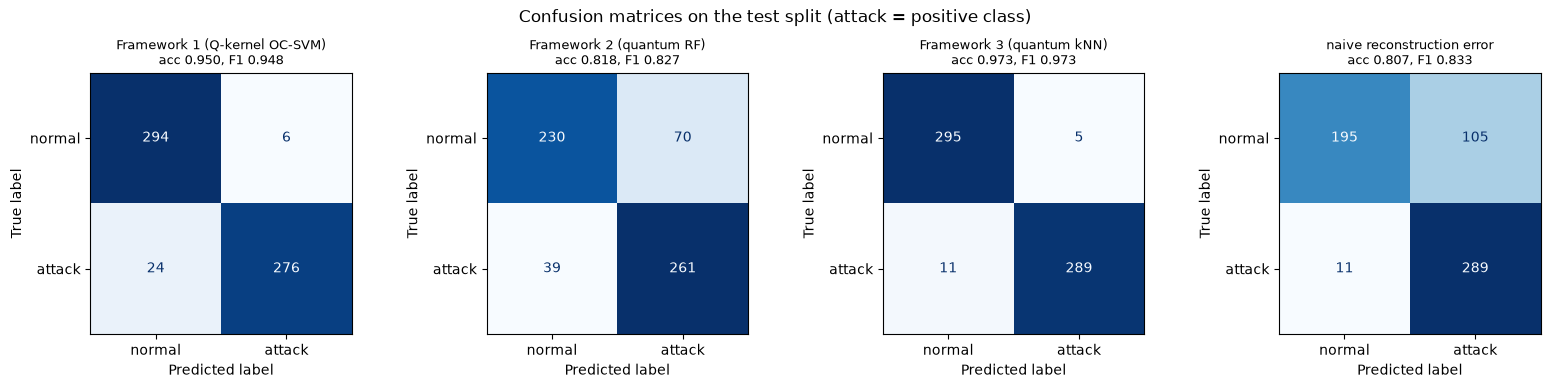

recall per attack family and false-alarm rate on normal test records (test counts: {'DoS': 282, 'Probe': 14, 'R2L': 4}, normal 300):


,DoS,Probe,R2L,false alarm rate (normal)
Framework 1,0.947,0.571,0.25,0.020
Framework 2,0.894,0.500,0.50,0.233
Framework 3,0.972,1.000,0.25,0.017
naive,0.968,0.857,1.00,0.350
OC-SVM (rbf) latent,0.968,0.786,0.25,0.027
RandomForest latent,0.968,0.929,0.25,0.010
kNN latent,0.972,1.000,0.25,0.017


In [14]:
rows_latent, preds_latent = evaluate_classical(L_train, y_train, L_test, y_test, "QAE latent")

summary_rows = [dict(model="Framework 1: QAE + quantum-kernel OC-SVM", inputs="QAE latent", fit_s=info_f1["fit_s"], predict_s=info_f1["predict_s"],
                     settings=f"scale={info_f1['scale']}, nu={info_f1['nu']}", **m_f1),
                dict(model="Framework 2: QAE + quantum random forest", inputs="QAE latent", fit_s=sum(info_f2["times"]), predict_s=np.nan,
                     settings=f"{QRF_TREES} trees x {QRF_BOOTSTRAP} rows, COBYLA {QRF_MAXITER}", **m_f2),
                dict(model="Framework 3: QAE + quantum kNN", inputs="QAE latent", fit_s=info_f3["states_s"], predict_s=info_f3["predict_s"],
                     settings=f"k={info_f3['k']}, {KNN_ENCODING} encoding", **m_f3),
                dict(model="Naive: QAE reconstruction error", inputs="QAE fidelity", fit_s=t_qae, predict_s=np.nan,
                     settings=f"fidelity < {naive_info['threshold']:.3f}", **m_naive)] + rows_latent + rows_pca
summary = pd.DataFrame(summary_rows)
print(f"QAE training time (shared by every 'QAE latent' model): {t_qae:.0f} s")
display(summary[["model", "inputs"] + METRICS + ["fit_s", "predict_s", "settings"]].round(4))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (name, pred) in zip(axes, [("Framework 1 (Q-kernel OC-SVM)", pred_f1), ("Framework 2 (quantum RF)", pred_f2),
                                   ("Framework 3 (quantum kNN)", pred_f3), ("naive reconstruction error", pred_naive)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]), display_labels=["normal", "attack"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nacc {accuracy_score(y_test, pred):.3f}, F1 {f1_score(y_test, pred):.3f}", fontsize=9)
plt.suptitle("Confusion matrices on the test split (attack = positive class)"); plt.tight_layout(); plt.show()

fam_rows = {}
for name, pred in [("Framework 1", pred_f1), ("Framework 2", pred_f2), ("Framework 3", pred_f3), ("naive", pred_naive),
                   ("OC-SVM (rbf) latent", preds_latent["OC-SVM (rbf)"]), ("RandomForest latent", preds_latent["RandomForest"]), ("kNN latent", preds_latent["kNN"])]:
    fam_rows[name] = {f: float(pred[(y_test == 1) & (meta_test.family == f).to_numpy()].mean())
                      for f in ["DoS", "Probe", "R2L", "U2R"] if ((y_test == 1) & (meta_test.family == f).to_numpy()).any()}
    fam_rows[name]["false alarm rate (normal)"] = float(pred[y_test == 0].mean())
per_family = pd.DataFrame(fam_rows).T
print("recall per attack family and false-alarm rate on normal test records (test counts: %s, normal %d):"
      % ({k: int(v) for k, v in meta_test[y_test == 1]["family"].value_counts().items()}, int((y_test == 0).sum())))
display(per_family.round(3))

## 12. Repeated balanced draws: mean +- std

With a few hundred test records every metric carries noise of a few points, and the paper's Table 1 is a single run. The
whole pipeline (draw, preprocessing, QAE training, latent features, Frameworks 1 and 3, the naive detector and the
classical models on both input sets) is repeated on `N_REPEATS - 1` further balanced draws with different seeds; draw 0
is the one above. Framework 2 (the slowest part) is run on draw 0 only. The table reports mean +- std over the draws.

In [15]:
def run_pipeline(seed):
    Xtr_raw, Xte_raw, ytr, yte, _ = balanced_draw(seed)
    Atr, Ate, _ = prepare(Xtr_raw, Xte_raw, N_DATA_QUBITS, seed)
    q = build_qae(); w, _ = train_qae(q, Atr[ytr == 0], seed=seed, verbose=False)
    ftr, fte = trash_fidelity(q, w, Atr), trash_fidelity(q, w, Ate)
    sc = MinMaxScaler((0.0, np.pi)).fit(latent_features(q, w, Atr))
    Ltr, Lte = sc.transform(latent_features(q, w, Atr)), np.clip(sc.transform(latent_features(q, w, Ate)), 0.0, np.pi)
    rows = [dict(model="Framework 1: QAE + quantum-kernel OC-SVM", inputs="QAE latent", **metrics(yte, framework1(Ltr, ytr, Lte, seed)[0])),
            dict(model="Framework 3: QAE + quantum kNN", inputs="QAE latent", **metrics(yte, framework3(Ltr, ytr, Lte, seed)[0])),
            dict(model="Naive: QAE reconstruction error", inputs="QAE fidelity", **metrics(yte, naive_detector(ftr, ytr, fte, seed)[0]))]
    rows += [dict(model=r["model"], inputs=r["inputs"], **{m: r[m] for m in METRICS}) for r in evaluate_classical(Ltr, ytr, Lte, yte, "QAE latent", seed)[0]]
    rows += [dict(model=r["model"], inputs=r["inputs"], **{m: r[m] for m in METRICS}) for r in evaluate_classical(Atr, ytr, Ate, yte, "PCA angles", seed)[0]]
    return [dict(seed=seed, fidelity_test_normal=float(fte[yte == 0].mean()), fidelity_test_attack=float(fte[yte == 1].mean()), **r) for r in rows]

t0 = time.perf_counter()
repeat_rows = [dict(seed=SEED, fidelity_test_normal=float(fid_test[y_test == 0].mean()), fidelity_test_attack=float(fid_test[y_test == 1].mean()),
                    model=r["model"], inputs=r["inputs"], **{m: r[m] for m in METRICS}) for r in summary_rows]
for rep in range(1, N_REPEATS):
    repeat_rows += run_pipeline(SEED + 100 * rep)
    print(f"draw {rep}/{N_REPEATS - 1} done ({time.perf_counter() - t0:.0f} s so far)")
repeats = pd.DataFrame(repeat_rows)
agg = repeats.groupby(["model", "inputs"], sort=False)[METRICS].agg(["mean", "std"])
agg.columns = [f"{m} {s}" for m, s in agg.columns]
agg["draws"] = repeats.groupby(["model", "inputs"], sort=False).size()
print(f"{N_REPEATS} balanced draws (Framework 2 on draw 0 only); mean +- std of the test metrics:")
display(agg.round(4))
print("QAE fidelity on unseen records, mean over draws: normal %.4f, attack %.4f"
      % (repeats.groupby("seed")["fidelity_test_normal"].first().mean(), repeats.groupby("seed")["fidelity_test_attack"].first().mean()))

draw 1/4 done (379 s so far)


draw 2/4 done (730 s so far)


draw 3/4 done (1005 s so far)


draw 4/4 done (1267 s so far)
5 balanced draws (Framework 2 on draw 0 only); mean +- std of the test metrics:


,,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std,draws
model,inputs,,,,,,,,,
Framework 1: QAE + quantum-kernel OC-SVM,QAE latent,0.9563,0.0106,0.9691,0.0164,0.9433,0.0326,0.9556,0.0114,5
Framework 2: QAE + quantum random forest,QAE latent,0.8183,NaN,0.7885,NaN,0.8700,NaN,0.8273,NaN,1
Framework 3: QAE + quantum kNN,QAE latent,0.9793,0.0056,0.9825,0.0028,0.9760,0.0101,0.9792,0.0057,5
Naive: QAE reconstruction error,QAE fidelity,0.8393,0.0233,0.7913,0.0427,0.9280,0.0460,0.8526,0.0173,5
RandomForest,QAE latent,0.9837,0.0071,0.9919,0.0039,0.9753,0.0122,0.9835,0.0073,5
SVC (rbf),QAE latent,0.9523,0.0103,0.9985,0.0033,0.9060,0.0188,0.9499,0.0112,5
kNN,QAE latent,0.9793,0.0056,0.9825,0.0028,0.9760,0.0101,0.9792,0.0057,5
OC-SVM (rbf),QAE latent,0.9590,0.0078,0.9700,0.0182,0.9480,0.0296,0.9584,0.0087,5
RandomForest,PCA angles,0.9847,0.0040,0.9892,0.0043,0.9800,0.0071,0.9846,0.0040,5


QAE fidelity on unseen records, mean over draws: normal 0.8935, attack 0.3012


## 13. Paper versus this notebook

Each row is one number of the paper for KDD99: the three frameworks of Table 1, the naive detector of Section 4, the
classical counterparts of Table 4 and the fidelities of Table 2. The verdict is **reproduced** when our value (draw 0, the
run shown above) is within 2 points (0.02) of the paper's, **exceeded** when it is more than 2 points above, **not
reached** when more than 2 points below, and **cannot be checked** for quantities that depend on the paper's hardware
or on datasets not run here. The mean over the repeated draws is shown next to draw 0 so that a verdict that rests on
noise can be recognised. The qualitative claims (every quantum framework beats its classical counterpart; Framework 1 is
the best framework on KDD99) are checked by comparing our own F1 values.

In [16]:
PAPER_TABLE1 = {"Framework 1: QAE + quantum-kernel OC-SVM": (0.9748, 0.9506, 0.9943, 0.9719),
                "Framework 2: QAE + quantum random forest": (0.9239, 0.8963, 0.9716, 0.9341),
                "Framework 3: QAE + quantum kNN":           (0.9173, 0.9089, 0.9634, 0.9315)}
PAPER_TABLE4 = {"OC-SVM (rbf)": (0.9021, 0.7853), "RandomForest": (0.8757, 0.9163), "kNN": (0.8528, 0.8430)}   # (accuracy, F1), QAE latent inputs
PAPER_NAIVE = (0.75, 0.77)
PAPER_TABLE2 = {(4, 2): 0.9963, (4, 3): 0.9812, (6, 4): 0.8610}
TOL = 0.02

def verdict(paper, ours, tol=TOL):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "cannot be checked"
    if abs(ours - paper) <= tol:
        return "reproduced"
    return "exceeded" if ours > paper else "not reached"

def ours(model, inputs, metric):
    r = summary[(summary.model == model) & (summary.inputs == inputs)]
    return float(r[metric].iloc[0]) if len(r) else None

def mean_over_draws(model, inputs, metric):
    r = agg.loc[(model, inputs)] if (model, inputs) in agg.index else None
    return None if r is None else float(r[f"{metric} mean"])

rows = []
for model, vals in PAPER_TABLE1.items():
    for metric, p in zip(METRICS, vals):
        o = ours(model, "QAE latent", metric)
        rows.append(dict(source="Table 1 (KDD99)", item=model, metric=metric, paper=p, notebook_draw0=round(o, 4), notebook_mean=round(mean_over_draws(model, "QAE latent", metric), 4), verdict=verdict(p, o)))
for metric, p in zip(["accuracy", "f1"], PAPER_NAIVE):
    o = ours("Naive: QAE reconstruction error", "QAE fidelity", metric)
    rows.append(dict(source="Section 4", item="Naive: QAE reconstruction error", metric=metric, paper=p, notebook_draw0=round(o, 4),
                     notebook_mean=round(mean_over_draws("Naive: QAE reconstruction error", "QAE fidelity", metric), 4), verdict=verdict(p, o)))
for model, vals in PAPER_TABLE4.items():
    for metric, p in zip(["accuracy", "f1"], vals):
        o = ours(model, "QAE latent", metric)
        rows.append(dict(source="Table 4 (classical, 10-fold CV)", item=model + " on QAE latent", metric=metric, paper=p, notebook_draw0=round(o, 4),
                         notebook_mean=round(mean_over_draws(model, "QAE latent", metric), 4), verdict=verdict(p, o)))
for (nd, nl), p in PAPER_TABLE2.items():
    if (nd, nl) == (N_DATA_QUBITS, N_LATENT):                       # the main QAE of Section 6 (QAE_EPOCHS epochs)
        o, ep = float(fid_train_normal.mean()), QAE_EPOCHS
    else:
        r = sweep_df[(sweep_df.data_qubits == nd) & (sweep_df.latent_qubits == nl) & (sweep_df.encoder_blocks == QAE_REPS)]
        o, ep = (float(r.fidelity_train_normal.iloc[0]) if len(r) else None), SWEEP_EPOCHS
    rows.append(dict(source="Table 2", item=f"QAE fidelity, {nd} data / {nl} latent qubits ({QAE_REPS} encoder blocks, {ep} epochs here)", metric="fidelity", paper=p,
                     notebook_draw0=None if o is None else round(o, 4), notebook_mean=None, verdict=verdict(p, o)))
rows.append(dict(source="Table 2", item="QAE training time 1.64 h / 1.49 h / 7.85 h", metric="time", paper=None,
                 notebook_draw0=f"{sweep_df.time_s.tolist()} s", notebook_mean=None, verdict="cannot be checked (hardware and epoch count unknown)"))
rows.append(dict(source="Table 1", item="IoT-23 and CICIoT2023 rows", metric="all", paper=None, notebook_draw0=None, notebook_mean=None,
                 verdict="cannot be checked (datasets not run here)"))
comparison = pd.DataFrame(rows)
display(comparison)
print(comparison[comparison.source.str.startswith("Table 1 (KDD99)")]["verdict"].value_counts().to_dict())

# qualitative claims, checked on our own numbers (F1, draw 0 and mean over draws)
claims = []
for fw, cl in [("Framework 1: QAE + quantum-kernel OC-SVM", "OC-SVM (rbf)"), ("Framework 2: QAE + quantum random forest", "RandomForest"), ("Framework 3: QAE + quantum kNN", "kNN")]:
    gap0 = ours(fw, "QAE latent", "f1") - ours(cl, "QAE latent", "f1")
    gm = mean_over_draws(fw, "QAE latent", "f1"); gm = None if gm is None else gm - mean_over_draws(cl, "QAE latent", "f1")
    v = "tie (within 2 points)" if abs(gap0) <= TOL else ("reproduced" if gap0 > 0 else "not reproduced (classical ahead)")
    claims.append(dict(claim=f"{fw.split(':')[0]} beats its classical counterpart ({cl}) on the same inputs",
                       notebook=f"F1 gap draw 0 {gap0:+.3f}" + ("" if gm is None else f", mean over draws {gm:+.3f}"), verdict=v))
f1s = {fw: ours(fw, "QAE latent", "f1") for fw in PAPER_TABLE1}
best = max(f1s, key=f1s.get)
claims.append(dict(claim="Framework 1 is the best framework on KDD99 (paper: 97.19 vs 93.41 / 93.15 F1)",
                   notebook="F1: " + ", ".join(f"{k.split(':')[0]} {v:.3f}" for k, v in f1s.items()),
                   verdict="reproduced" if best.startswith("Framework 1") else f"not reproduced ({best.split(':')[0]} is best here)"))
claims.append(dict(claim="Framework 3 is the best framework on the IoT datasets", notebook="", verdict="cannot be checked (datasets not run here)"))
claims.append(dict(claim="Naive reconstruction-error detector is clearly worse than the frameworks (paper: 75 % / 77 % vs 92-97 %)",
                   notebook=f"naive F1 {m_naive['f1']:.3f} vs best framework F1 {max(f1s.values()):.3f}",
                   verdict="reproduced" if max(f1s.values()) - m_naive["f1"] > TOL else "not reproduced (naive detector within 2 points or better)"))
display(pd.DataFrame(claims))
print(f"total notebook runtime: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min (FAST_MODE = {FAST_MODE}, data source: {DATA_SOURCE})")

,source,item,metric,paper,notebook_draw0,notebook_mean,verdict
0,Table 1 (KDD99),Framework 1: QAE + quantum-kernel OC-SVM,accuracy,0.9748,0.95,0.9563,not reached
1,Table 1 (KDD99),Framework 1: QAE + quantum-kernel OC-SVM,precision,0.9506,0.9787,0.9691,exceeded
2,Table 1 (KDD99),Framework 1: QAE + quantum-kernel OC-SVM,recall,0.9943,0.92,0.9433,not reached
3,Table 1 (KDD99),Framework 1: QAE + quantum-kernel OC-SVM,f1,0.9719,0.9485,0.9556,not reached
4,Table 1 (KDD99),Framework 2: QAE + quantum random forest,accuracy,0.9239,0.8183,0.8183,not reached
5,Table 1 (KDD99),Framework 2: QAE + quantum random forest,precision,0.8963,0.7885,0.7885,not reached
6,Table 1 (KDD99),Framework 2: QAE + quantum random forest,recall,0.9716,0.87,0.8700,not reached
7,Table 1 (KDD99),Framework 2: QAE + quantum random forest,f1,0.9341,0.8273,0.8273,not reached
8,Table 1 (KDD99),Framework 3: QAE + quantum kNN,accuracy,0.9173,0.9733,0.9793,exceeded
9,Table 1 (KDD99),Framework 3: QAE + quantum kNN,precision,0.9089,0.983,0.9825,exceeded


{'not reached': 7, 'exceeded': 4, 'reproduced': 1}


,claim,notebook,verdict
0,Framework 1 beats its classical counterpart (O...,"F1 gap draw 0 -0.013, mean over draws -0.003",tie (within 2 points)
1,Framework 2 beats its classical counterpart (R...,"F1 gap draw 0 -0.146, mean over draws -0.156",not reproduced (classical ahead)
2,Framework 3 beats its classical counterpart (k...,"F1 gap draw 0 +0.000, mean over draws +0.000",tie (within 2 points)
3,Framework 1 is the best framework on KDD99 (pa...,"F1: Framework 1 0.948, Framework 2 0.827, Fram...",not reproduced (Framework 3 is best here)
4,Framework 3 is the best framework on the IoT d...,,cannot be checked (datasets not run here)
5,Naive reconstruction-error detector is clearly...,naive F1 0.833 vs best framework F1 0.973,reproduced


total notebook runtime: 42.0 min (FAST_MODE = False, data source: KDD99 10 % (kddcup.data_10_percent))


## Reading the paper critically

**The "quantum" in the three frameworks is a similarity measure, not an algorithm with a speed-up.** Framework 1 is a
classical one-class SVM whose kernel entries are circuit fidelities; Framework 3 is a classical kNN whose distance is a
circuit fidelity; Framework 2 is classical bagging over variational classifiers. For angle-encoded product states the
fidelity is $\prod_i \cos^2((a_i - b_i)/2)$, a smooth kernel that a laptop evaluates in nanoseconds; the ZZFeatureMap
kernel is harder to compute classically but, as Section 8 shows, needs a bandwidth to work at all. None of this is
wrong, but the paper's discussion of "quantum speedup" and "quantum superposition" (Section 7) describes algorithms that
were not run; on the simulator and on `ibmq_lima` every record was processed one circuit at a time, which is why Table 2
reports hours for a 4-qubit model that trains in seconds here.

**The frameworks are not unsupervised.** The paper frames the task as unsupervised anomaly detection and trains the QAE
on normal data only, which is sound. But the quantum random forest and the quantum kNN are supervised classifiers that
need labelled attacks in their training data (a bootstrap sample with a single class cannot train a VQC; a kNN with only
normal neighbours never predicts "attack"). Only Framework 1 and the naive detector are true one-class detectors. Table 1
therefore compares a one-class method with two supervised methods on the same balanced test set, which is not the
comparison its text suggests, and the supervised models cannot be expected to detect attack types absent from training.

**Sample sizes, qubit counts and the pipeline between QAE and classifier are not stated.** The paper never says how many
of the 4.9 M records were used after undersampling, how the compressed state was turned into the classifier's input
(a measured 2-qubit state is two bits; this notebook reads expectation values), how many trees the forest has, which $k$
the kNN uses, or which $\nu$ the one-class SVM has; "4 total qubits and 2 latent qubits" (Table 2) and the 4-wire Fig. 4
(control, reference, trash, latent, i.e. 2 data qubits and 1 latent) describe different circuits; in the Table 2 sweep of
Section 6 the literal Fig. 4 circuit reaches a fidelity much closer to the paper's 0.98-0.99 than the 4-data-qubit
model does, which suggests that the paper's QAE compressed two features into one qubit. Every one of these
choices moves the accuracy by several points (compare the single trees of Section 9 with their vote, or the $\nu$ /
bandwidth grid of Section 8), so Table 1 can be approached but not reproduced exactly; the verdicts above say how close
this notebook's documented choices come.

**Table 4 does not match its own description.** The classical counterparts are reported with 10-fold cross-validation
and "averaged over 5 iterations" while the quantum frameworks use a single 80 : 20 split; the SVM row has an F1 (78.53 %)
twelve points below its accuracy (90.21 %) on data the paper says was balanced by undersampling, which happens only if the
model misses many attacks, and the RF row has an F1 above its accuracy. The claim that "quantum frameworks consistently
outperformed the classical ML classifiers" rests on this table. On identical inputs with the same tuning budget, Section 11
shows how large the gap really is.

**A single run, no interval.** Table 1 reports one number per cell. With $n$ test records the standard error of an
accuracy near 0.95 is $\sqrt{0.95 \cdot 0.05 / n}$, about 1.7 points for 160 records and 0.9 points for 600; Section 12
shows the spread between balanced draws directly. Differences of two or three points between the frameworks, such as
92.39 % versus 91.73 %, are not distinguishable from noise without more runs.

**KDD99 is an easy, dated benchmark.** The 10 % file is 78 % `smurf` and `neptune` floods and 70 % exact duplicates;
with the dataset's own attack mix most attacks are DoS floods that even the naive detector spots, while the per-family
table of Section 11 shows that R2L and U2R attacks (a handful of records) are a different story. Results on this
dataset say little about the IoT-23 and CICIoT2023 numbers in Table 1, which this notebook does not attempt.

## Exercises

1. **Attack mix.** Set `ATTACK_SAMPLING = "family"` so that DoS, Probe, R2L and U2R attacks are drawn in equal shares.
   Which framework loses the most, and what does the per-family table of Section 11 show now? Relate the answer to the
   claim that anomaly detection "detects unknown attacks".
2. **The literal Fig. 4 circuit.** Set `N_DATA_QUBITS = 2`, `N_LATENT = 1` (the 4-wire circuit) and rerun. Compare the
   fidelities and the detection metrics with the 4 / 2 configuration and with the (2, 1) row of the Table 2 sweep. Is the
   paper's 0.9963 fidelity easier or harder to reach with fewer qubits, and why?
3. **What the latent read-out hides.** Change `LATENT_OBS` to `("Z",)` (two numbers per record) and to `("Z", "X", "Y")`.
   How do the three frameworks and the classical counterparts react? Which read-out would a real device need, and how
   many shots?
4. **An honest one-class comparison.** Framework 2 and 3 are supervised. Build a one-class version of Framework 3: keep
   only normal training states and flag a test record when its mean fidelity to its $k$ nearest normal neighbours is
   below a threshold chosen on the inner validation split. Compare it with Framework 1 and with the naive detector.
5. **Kernel bandwidth and $\nu$.** Print the full `SCALE_GRID` x `NU_GRID` validation table inside `framework1`. How
   much does the inner-validation F1 move across the grid, and how does that range compare with the gaps between the
   frameworks in Table 1? Then set `FM_REPS = 2` and see whether the sharper kernel can still be tuned.